# Literature retrieval and evidence-grounded QA

This notebook shows source preparation, retrieval, supervised model/loss/training,
complete validation and source-citation checks. Definitions below mirror the
production modules; their source fingerprints identify the implementation.
Tables and figures use actual full-cohort aggregates and recorded pretrained-model
continuation checks. These mechanics checks are not answer-accuracy estimates.

Use a fresh environment with `pip install -e ".[reader,models,notebook]"`.
Optional downloads, fresh training and neural inference are disabled by default.
Notebook training records an additional code-cell fingerprint and uses a fresh
output; recorded cloud results are never represented as notebook training.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run in this repository"
FIGURES = ROOT / "assets/plots"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "svg.fonttype": "none",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


def table(rows, columns, caption):
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join("<td>" + html.escape(str(r.get(c, ""))) + "</td>" for c in columns)
        + "</tr>"
        for r in rows
    )
    display(
        HTML(
            "<table><caption>"
            + html.escape(caption)
            + "</caption><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=160)
    fig.savefig(FIGURES / (name + ".svg"))
    svg_path = FIGURES / (name + ".svg")
    svg_path.write_text(
        "\n".join(
            line.rstrip() for line in svg_path.read_text(encoding="utf-8").splitlines()
        )
        + "\n",
        encoding="utf-8",
        newline="\n",
    )
    display(SVG(svg_path.read_text(encoding="utf-8")))
    plt.close(fig)


print("Analysis kernel ready. No model weights loaded.")


def notebook_source_sha256():
    document = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    cells = [(c["cell_type"], c["source"]) for c in document["cells"]]
    return sha(json.dumps(cells, sort_keys=True).encode())


Analysis kernel ready. No model weights loaded.


In [2]:
NOTEBOOK_PATH = ROOT / "notebooks/00_main_literature_rag.ipynb"
DATA = ROOT / "data"
STAGED = DATA / "interim/full-fairytale-v6"
PROTOCOL = ROOT / "docs/full-coverage-protocol.json"
RUN_DIR = (
    ROOT
    / "models"
    / ("notebook-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
)
RUN_PREPARE = False
RUN_DOWNLOAD = False
RUN_HYBRID = False
RUN_READER = False
RUN_TRAIN = False
RUN_RERANKER_TRAIN = False
RUN_VALIDATION_SELECTION = False
BOOKS = {
    "pride": {
        "id": 1342,
        "title": "Pride and Prejudice",
        "author": "Jane Austen",
        "death": 1817,
    },
    "frankenstein": {
        "id": 84,
        "title": "Frankenstein",
        "author": "Mary Shelley",
        "death": 1851,
    },
}
DENSE_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
RERANKER_REVISION = "233902d25c440f23af6f7d6e94d2946bac0bee0a"
MODEL = "deepset/minilm-uncased-squad2"
REVISION = "934656cdda79824eabf503ed56e15c01ddbdbe3f"
print("Model training/inference require explicit switches; test scoring is excluded.")


Model training/inference require explicit switches; test scoring is excluded.


## 1. Source preparation and exact passage geometry

The Gutenberg pipeline preserves its original serialization for citation replay.
Docling conversion is opt-in. FairytaleQA uses its edited section text and exact
dataset offsets, not asserted Gutenberg edition offsets. All Lang-origin groups
stay together because the Blue label contains stories from other Lang books.


In [3]:
def strip_gutenberg(text):
    start = re.search(
        r"\*\*\* START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", text
    )
    end = re.search(r"\*\*\* END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK", text)
    if not start or not end or end.start() <= start.end():
        raise ValueError("Expected Gutenberg license boundary markers are missing")
    return text[start.end() : end.start()].strip()


def write_processed(path, body):
    """Freeze original Windows CRLF-v1 serialization for cross-platform citation replay.

    Existing CRLF in Gutenberg bodies is intentionally preserved by this legacy
    representation. Hash/read offsets use actual postwrite universal-newline text.
    Changing this serialization requires a new representation version and index.
    """
    path.write_text(body, encoding="utf-8", newline="\r\n")


def fetch(acknowledge=False, root=DATA):
    if not acknowledge:
        raise ValueError(
            "Check local copyright law and pass --acknowledge-local-rights"
        )
    records = []
    for key, meta in BOOKS.items():
        url = f"https://www.gutenberg.org/ebooks/{meta['id']}.txt.utf-8"
        req = urllib.request.Request(
            url, headers={"User-Agent": "LiteraryResearch/0.1"}
        )
        raw = urllib.request.urlopen(req, timeout=60).read()
        body = strip_gutenberg(raw.decode("utf-8-sig"))
        for folder in ("raw", "processed", "external", "interim"):
            (root / folder).mkdir(parents=True, exist_ok=True)
        (root / "raw" / f"{key}.txt").write_bytes(raw)
        write_processed(root / "processed" / f"{key}.txt", body)
        records.append(
            dict(
                meta,
                key=key,
                url=url,
                sha256=hashlib.sha256(raw).hexdigest(),
                bytes=len(raw),
            )
        )
    (root / "external" / "manifest.json").write_text(
        json.dumps(records, indent=2), encoding="utf-8"
    )
    return records


def ingest_document(path):
    path = Path(path)
    if path.suffix.lower() in {".txt", ".md"}:
        return path.read_text(encoding="utf-8")
    from docling.document_converter import DocumentConverter

    converted = DocumentConverter().convert(str(path)).document.export_to_markdown()
    if not converted.strip():
        raise ValueError("Document conversion produced no text")
    return converted


In [4]:
# Production source: src/data/full_coverage_audit.py
"""Audit all pinned FairytaleQA sources without parsing any question/answer CSV."""

import argparse
from collections import defaultdict
import csv
import json
from pathlib import Path
import urllib.request
import zipfile
from src.data.prepare_fairytale import normalized, sha, shingles

FAIRYTALE_REVISION = "a24ddc17364666b7c13a425b9970c87368b03417"
VALIDATION = {
    "andersen-fairybook",
    "blue-fairybook",
    "green-fairybook",
    "lilac-fairybook",
}
TEST = {"grimm-fairybook", "beatrix-potter-fairybook"}
ARCHIVE_SHA256 = "353ec962a911ea9b2a4fbba2fe9fdebe2a92c392ce4be36194f2062f0ac9a998"


def fetch_source(output):
    """Fetch the immutable official archive; extract data/attribution files only."""
    output = Path(output)
    if output.exists():
        raise ValueError("Preserve existing source downloads")
    output.mkdir(parents=True)
    archive = output / "source.zip"
    url = (
        "https://codeload.github.com/uci-soe/FairytaleQAData/zip/" + FAIRYTALE_REVISION
    )
    with urllib.request.urlopen(url, timeout=120) as response, archive.open(
        "wb"
    ) as handle:
        while block := response.read(1024 * 1024):
            handle.write(block)
    if sha(archive.read_bytes()) != ARCHIVE_SHA256:
        raise ValueError("Pinned official archive hash changed")
    prefix = "FairytaleQAData-" + FAIRYTALE_REVISION + "/"
    with zipfile.ZipFile(archive) as bundle:
        for member in bundle.infolist():
            if not member.filename.startswith(prefix):
                raise ValueError("Unexpected archive root")
            relative = member.filename[len(prefix) :]
            if not relative or member.is_dir():
                continue
            if (
                "\\" in relative
                or Path(relative).is_absolute()
                or ".." in Path(relative).parts
                or (":" in relative)
            ):
                raise ValueError("Unsafe archive member")
            if relative not in ("LICENSE", "README.md", "story_meta.csv") and (
                not relative.startswith(
                    (
                        "data-by-train-split/section-stories/",
                        "data-by-train-split/questions/",
                    )
                )
            ):
                continue
            destination = output / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(bundle.read(member))
    return output


def source_sections(path):
    """Merge adjacent repeated source IDs, retaining every paragraph and offsets.

    The official remarkable-rocket CSV has consecutive, distinct paragraphs
    sharing ID 5. Gold references identify that ID, so its complete text is one
    evidence unit; no unsupported choice of a single paragraph is made.
    """
    with Path(path).open(encoding="utf-8-sig", newline="") as handle:
        rows = list(csv.DictReader(handle))
    grouped = []
    for row in rows:
        identity, text = (row["section"], row["text"])
        if not identity or not text.strip():
            raise ValueError("Empty source section")
        if grouped and grouped[-1]["id"] == identity:
            grouped[-1]["text"] += "\n\n" + text
        else:
            grouped.append({"id": identity, "text": text})
    if len({r["id"] for r in grouped}) != len(grouped):
        raise ValueError("Nonadjacent repeated section ID is ambiguous")
    offset = 0
    for row in grouped:
        row.update(start=offset, end=offset + len(row["text"]))
        offset = row["end"] + 2
    return (grouped, len(rows) - len(grouped))


def audit(source, previous_manifest):
    source = Path(source)
    with (source / "story_meta.csv").open(encoding="utf-8", newline="") as handle:
        metadata = list(csv.DictReader(handle))
    old = json.loads(Path(previous_manifest).read_text(encoding="utf-8"))
    old_roles = {r["id"]: r["split"] for r in old["stories"]}
    items = []
    for row in metadata:
        path = (
            source
            / "data-by-train-split/section-stories"
            / row["split"]
            / (row["filename"] + "-story.csv")
        )
        sections, merged = source_sections(path)
        text = "\n\n".join((r["text"] for r in sections))
        role = (
            "validation"
            if row["origin"] in VALIDATION
            else "test" if row["origin"] in TEST else "train"
        )
        items.append(
            {
                "id": row["filename"],
                "origin": row["origin"],
                "official": row["split"],
                "QA_metadata": int(row["questions"]),
                "role": role,
                "norm": normalized(text),
                "grams": shingles(text),
                "source_sha256": sha(text.encode()),
                "source_file_sha256": sha(path.read_bytes()),
                "adjacent_duplicate_rows_merged": merged,
            }
        )
    parents = list(range(len(items)))

    def find(i):
        while parents[i] != i:
            parents[i] = parents[parents[i]]
            i = parents[i]
        return i

    edges = []
    for i, left in enumerate(items):
        for j in range(i):
            right = items[j]
            reason = None
            if normalized(left["id"]) == normalized(right["id"]):
                reason, overlap = ("normalized title", 1.0)
            elif left["norm"] == right["norm"]:
                reason, overlap = ("normalized text", 1.0)
            else:
                overlap = len(left["grams"] & right["grams"]) / max(
                    1, len(left["grams"] | right["grams"])
                )
                if overlap >= 0.8:
                    reason = "five-token Jaccard >= .8"
            if reason:
                parents[find(i)] = find(j)
                edges.append(
                    {
                        "left": left["id"],
                        "right": right["id"],
                        "reason": reason,
                        "overlap": overlap,
                    }
                )
    groups = defaultdict(list)
    for i, row in enumerate(items):
        groups[find(i)].append(row)
    priority = {"train": 0, "validation": 1, "test": 2}
    migrations = []
    for group in groups.values():
        role = max((r["role"] for r in group), key=priority.get)
        for row in group:
            if row["role"] != role:
                migrations.append(
                    {"id": row["id"], "previous_role": row["role"], "new_role": role}
                )
            row["role"] = role
    inventory = [
        {k: v for k, v in row.items() if k not in ("norm", "grams")} for row in items
    ]

    def counts(key, values):
        return {
            value: {
                "stories": sum((r[key] == value for r in items)),
                "QA_metadata": sum(
                    (r["QA_metadata"] for r in items if r[key] == value)
                ),
            }
            for value in values
        }

    return {
        "source_revision": FAIRYTALE_REVISION,
        "metadata_sha256": sha((source / "story_meta.csv").read_bytes()),
        "license_sha256": sha((source / "LICENSE").read_bytes()),
        "official_counts": counts("official", ("train", "val", "test")),
        "full_source_family_counts": counts("role", ("train", "validation", "test")),
        "by_origin": counts("origin", sorted({r["origin"] for r in items})),
        "duplicate_edges": edges,
        "duplicate_group_migrations": migrations,
        "prior_observed_role_migrations": [
            {"id": r["id"], "old": old_roles[r["id"]], "new": r["role"]}
            for r in items
            if r["id"] in old_roles and old_roles[r["id"]] != r["role"]
        ],
        "old_study_counts": {
            "train_QA": 3314,
            "validation_QA_total": 2372,
            "validation_QA_scored": 400,
            "sealed_test_QA_metadata": 325,
        },
        "source_inventory": inventory,
        "QA_files_parsed": False,
        "test_answers_inspected": False,
        "count_basis": "Pinned official story metadata; no test CSV parsing",
        "raw_text_or_answers_published": False,
    }


def stage(source, output, audit_path, protocol_path):
    """Stage every audited story and QA CSV; test CSV is copied as bytes only."""
    source, output = (Path(source), Path(output))
    if output.exists():
        raise ValueError("Preserve previous staging; use a new output directory")
    report = json.loads(Path(audit_path).read_text(encoding="utf-8"))
    protocol = json.loads(Path(protocol_path).read_text(encoding="utf-8"))
    dataset = protocol["dataset"]
    if dataset["audit_normalized_utf8_sha256"] != sha(
        Path(audit_path).read_text(encoding="utf-8").encode()
    ):
        raise ValueError("Changed full coverage audit")
    if (
        sha((source / "story_meta.csv").read_bytes()) != report["metadata_sha256"]
        or sha((source / "LICENSE").read_bytes()) != report["license_sha256"]
    ):
        raise ValueError("Changed pinned metadata or dataset license")
    if dataset["full_coverage"]["custom"] != report["full_source_family_counts"]:
        raise ValueError("Protocol/audit coverage mismatch")
    output.mkdir(parents=True)
    stories = []
    for item in report["source_inventory"]:
        name, official, role = (item["id"], item["official"], item["role"])
        source_path = (
            source
            / "data-by-train-split/section-stories"
            / official
            / (name + "-story.csv")
        )
        if sha(source_path.read_bytes()) != item["source_file_sha256"]:
            raise ValueError("Changed audited story")
        sections, _ = source_sections(source_path)
        text = "\n\n".join((row["text"] for row in sections))
        if sha(text.encode()) != item["source_sha256"]:
            raise ValueError("Changed processed source")
        qa_path = (
            source
            / "data-by-train-split/questions"
            / official
            / (name + "-questions.csv")
        )
        raw_qa = qa_path.read_bytes()
        story = {
            "id": name,
            "origin": item["origin"],
            "split": role,
            "official_split": official,
            "sections": sections,
            "text": text,
            "source_sha256": item["source_sha256"],
            "qa_sha256": sha(raw_qa),
        }
        directory = output / role
        directory.mkdir(exist_ok=True)
        (directory / (name + ".qa.csv")).write_bytes(raw_qa)
        (directory / (name + ".story.json")).write_text(
            json.dumps(story, ensure_ascii=False), encoding="utf-8", newline="\n"
        )
        stories.append(
            {
                k: story[k]
                for k in (
                    "id",
                    "origin",
                    "split",
                    "official_split",
                    "source_sha256",
                    "qa_sha256",
                )
            }
        )
    manifest = {
        "stories": stories,
        "source_revision": FAIRYTALE_REVISION,
        "protocol_sha256": sha(Path(protocol_path).read_bytes()),
        "audit_normalized_utf8_sha256": dataset["audit_normalized_utf8_sha256"],
        "counts_metadata": report["full_source_family_counts"],
        "QA_parsed": False,
        "test_QA_copied_as_bytes_only": True,
        "source_family_split_not_official_benchmark": True,
    }
    (output / "manifest.json").write_text(
        json.dumps(manifest, indent=2) + "\n", encoding="utf-8", newline="\n"
    )
    return manifest


In [5]:
@dataclass
class Passage:
    id: str
    book: str
    start: int
    end: int
    text: str
    progress: float


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def chunk_book(book, text, words=180, overlap=40):
    if words < 2 or not 0 <= overlap < words:
        raise ValueError("Require words >= 2 and 0 <= overlap < words")
    spans = list(re.finditer(r"\S+", text))
    result = []
    for i in range(0, len(spans), words - overlap):
        j = min(i + words, len(spans))
        start, end = spans[i].start(), spans[j - 1].end()
        result.append(
            Passage(
                f"{book}:{start}-{end}",
                book,
                start,
                end,
                text[start:end],
                i / max(1, len(spans)),
            )
        )
        if j == len(spans):
            break
    return result


In [6]:
policy = read_json("docs/full-coverage-protocol.json")
source_dir = DATA / "external/full-fairytale-verified"
if RUN_DOWNLOAD:
    fetch_source(source_dir)
if RUN_PREPARE:
    stage(source_dir, STAGED, read_json("docs/full-coverage-audit.json"), policy)
summary = read_json("docs/data-summary.json")
assert (
    summary["staging_manifest_sha256"]
    == "721733169b0c1e7b7c1d07fe1880d3c871d72017be6fc61923be126feea73225"
)
table(
    [
        {
            "split": k,
            "stories": v["stories"],
            "QA metadata": v["metadata_qa"],
            "median words": v["median_words"],
        }
        for k, v in summary["source_lengths"].items()
        if k != "excluded"
    ],
    ["split", "stories", "QA metadata", "median words"],
    "Complete source-family cohort; test labels not parsed",
)
print("Source revision:", summary["dataset_revision"])


split,stories,QA metadata,median words
train,200,7883,2037.0
validation,54,2372,1837.0
test,24,325,1040.0


Source revision: a24ddc17364666b7c13a425b9970c87368b03417


## 2. Hybrid search, persistence and cross-book evidence

This is the complete BM25/LSA/pretrained-dense implementation, including reciprocal
rank fusion and safe JSON/NPZ persistence. LSA is a fitted corpus baseline, not a
pretrained language model. Neural search requires an exact embedding revision.
Similarity proposes passages to compare; it does not prove a literary claim.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize


In [8]:
@lru_cache(maxsize=2)
def encoder(model_name, revision=None):
    from sentence_transformers import SentenceTransformer
    import torch

    torch.set_num_threads(2)
    return SentenceTransformer(model_name, revision=revision, trust_remote_code=False)


@lru_cache(maxsize=2)
def cross_encoder(model_name):
    from sentence_transformers import CrossEncoder
    import torch

    torch.set_num_threads(2)
    revision = (
        RERANKER_REVISION
        if model_name == "cross-encoder/ms-marco-MiniLM-L-6-v2"
        else None
    )
    return CrossEncoder(model_name, revision=revision, trust_remote_code=False)


class HybridIndex:
    def __init__(
        self,
        passages,
        backend="lsa",
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_revision=None,
    ):
        if not passages:
            raise ValueError("Cannot index an empty corpus")
        self.passages, self.backend, self.model_name = passages, backend, model_name
        self.model_revision = model_revision or (
            DENSE_REVISION
            if model_name == "sentence-transformers/all-MiniLM-L6-v2"
            else None
        )
        if backend == "sentence-transformer" and (
            not self.model_revision
            or not re.fullmatch(r"[0-9a-f]{40}", self.model_revision)
        ):
            raise ValueError(
                "Neural embeddings require an exact 40-character model commit revision"
            )
        self.tf = [Counter(tokenize(p.text)) for p in passages]
        self.lengths = np.array([sum(c.values()) for c in self.tf])
        self.avglen = max(1, self.lengths.mean())
        self.df = Counter(t for c in self.tf for t in c)
        if backend == "lsa":
            self.vectorizer = TfidfVectorizer(
                stop_words="english", min_df=1, sublinear_tf=True
            )
            matrix = self.vectorizer.fit_transform(p.text for p in passages)
            n = min(128, matrix.shape[0] - 1, matrix.shape[1] - 1)
            if n < 1:
                raise ValueError("Need two passages and distinct vocabulary terms")
            self.svd = TruncatedSVD(n_components=n, random_state=42)
            self.dense = normalize(self.svd.fit_transform(matrix))
        elif backend == "sentence-transformer":
            self.dense = self._encoder().encode(
                [p.text for p in passages], normalize_embeddings=True
            )
        else:
            raise ValueError("Unknown embedding backend")

    def _encoder(self):
        revision = getattr(self, "model_revision", None)
        if not revision or not re.fullmatch(r"[0-9a-f]{40}", revision):
            raise ValueError(
                "Neural index lacks an exact model revision; re-encode it before querying"
            )
        return encoder(self.model_name, revision)

    def search(
        self, query, k=6, book=None, reranker=None, mode="hybrid", min_dense=None
    ):
        if not isinstance(query, str) or not isinstance(k, int):
            raise ValueError("Query must be text and k must be an integer")
        if mode not in {"hybrid", "bm25", "dense"}:
            raise ValueError("Unknown retrieval mode")
        if not tokenize(query) or k < 1:
            return []
        bm = np.zeros(len(self.passages))
        for term in set(tokenize(query)):
            df = self.df[term]
            idf = math.log(1 + (len(bm) - df + 0.5) / (df + 0.5))
            f = np.array([c[term] for c in self.tf])
            bm += idf * f * 2.5 / (f + 1.5 * (0.25 + 0.75 * self.lengths / self.avglen))
        if self.backend == "lsa":
            q = normalize(self.svd.transform(self.vectorizer.transform([query])))
        else:
            q = self._encoder().encode([query], normalize_embeddings=True)
        dense = (self.dense @ q.T).ravel()
        eligible = [
            i
            for i, p in enumerate(self.passages)
            if (book is None or p.book == book)
            and (
                bm[i] > 0
                if mode == "bm25"
                else (
                    dense[i] > 1e-8 if mode == "dense" else bm[i] > 0 or dense[i] > 1e-8
                )
            )
        ]
        if min_dense is not None:
            eligible = [i for i in eligible if dense[i] >= min_dense]
        fused = {i: 0.0 for i in eligible}
        rankings = (
            (bm, dense) if mode == "hybrid" else (bm,) if mode == "bm25" else (dense,)
        )
        for scores in rankings:
            for rank, i in enumerate(
                sorted(eligible, key=lambda i: (-scores[i], i)), 1
            ):
                fused[i] += 1 / (60 + rank)
        candidates = sorted(eligible, key=lambda i: (-fused[i], i))[
            : max(k, 30) if reranker else k
        ]
        if reranker and candidates:
            scores = cross_encoder(reranker).predict(
                [(query, self.passages[i].text) for i in candidates],
                batch_size=8,
                show_progress_bar=False,
            )
            candidates = [i for _, i in sorted(zip(scores, candidates), reverse=True)][
                :k
            ]
        return [(self.passages[i], fused[i]) for i in candidates[:k]]

    def save(self, path):
        if self.backend == "sentence-transformer" and (
            not getattr(self, "model_revision", None)
            or not re.fullmatch(r"[0-9a-f]{40}", self.model_revision)
        ):
            raise ValueError(
                "Cannot persist neural index without exact embedding revision"
            )
        path.parent.mkdir(parents=True, exist_ok=True)
        metadata = {
            "schema": 1,
            "backend": self.backend,
            "model_name": self.model_name,
            "model_revision": getattr(self, "model_revision", None),
            "chunk_contract": getattr(self, "chunk_contract", None),
            "passages": [asdict(p) for p in self.passages],
            "source_hashes": getattr(self, "source_hashes", {}),
        }
        arrays = {"dense": self.dense}
        if self.backend == "lsa":
            metadata["vocabulary"] = self.vectorizer.vocabulary_
            arrays["idf"] = self.vectorizer.idf_
            arrays["components"] = self.svd.components_
        buffer = io.BytesIO()
        np.savez_compressed(buffer, **arrays)
        with zipfile.ZipFile(path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
            archive.writestr("metadata.json", json.dumps(metadata))
            archive.writestr("arrays.npz", buffer.getvalue())

    @staticmethod
    def load(path, allow_missing_revision=False):
        # No pickle or executable deserialization. Legacy .pkl files require rebuilding.
        try:
            with zipfile.ZipFile(path) as archive:
                if (
                    set(archive.namelist()) != {"metadata.json", "arrays.npz"}
                    or sum(i.file_size for i in archive.infolist()) > 512_000_000
                ):
                    raise ValueError("Invalid or oversized index archive")
                meta = json.loads(archive.read("metadata.json"))
                if meta.get("schema") != 1 or meta.get("backend") not in {
                    "lsa",
                    "sentence-transformer",
                }:
                    raise ValueError("Unsupported index schema")
                npz = archive.read("arrays.npz")
                with zipfile.ZipFile(io.BytesIO(npz)) as inner:
                    if sum(i.file_size for i in inner.infolist()) > 512_000_000:
                        raise ValueError("Oversized embedding arrays")
                    for entry in inner.infolist():
                        with inner.open(entry) as file:
                            version = np.lib.format.read_magic(file)
                            shape, _, dtype = (
                                np.lib.format.read_array_header_1_0(file)
                                if version == (1, 0)
                                else np.lib.format.read_array_header_2_0(file)
                            )
                            if (
                                dtype.hasobject
                                or np.prod(shape, dtype=object) * dtype.itemsize
                                > 512_000_000
                            ):
                                raise ValueError("Unsafe embedding array header")
                arrays = np.load(io.BytesIO(npz), allow_pickle=False)
                expected = (
                    {"dense", "idf", "components"}
                    if meta["backend"] == "lsa"
                    else {"dense"}
                )
                if set(arrays.files) != expected:
                    raise ValueError("Unexpected index arrays")
                if any(
                    arrays[name].dtype.kind not in "fiu"
                    or not np.isfinite(arrays[name]).all()
                    for name in arrays.files
                ):
                    raise ValueError("Non-numeric or non-finite index arrays")
                index = HybridIndex.__new__(HybridIndex)
                index.passages = [Passage(**p) for p in meta["passages"]]
                if not index.passages:
                    raise ValueError("Empty index corpus")
                index.backend = meta["backend"]
                index.model_name = meta["model_name"]
                index.model_revision = meta.get("model_revision")
                if (
                    index.backend == "sentence-transformer"
                    and (
                        not index.model_revision
                        or not re.fullmatch(r"[0-9a-f]{40}", index.model_revision)
                    )
                    and not allow_missing_revision
                ):
                    raise ValueError(
                        "Neural index is missing an exact model revision; re-encode legacy artifacts"
                    )
                index.source_hashes = meta.get("source_hashes", {})
                index.chunk_contract = meta.get("chunk_contract")
                index.dense = arrays["dense"].copy()
                if (
                    index.dense.ndim != 2
                    or index.dense.shape[0] != len(index.passages)
                    or not np.isfinite(index.dense).all()
                ):
                    raise ValueError("Invalid embedding matrix")
                if len({p.id for p in index.passages}) != len(index.passages):
                    raise ValueError("Duplicate passage identifiers")
                if any(
                    not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_-]*", p.book)
                    or p.start < 0
                    or p.end <= p.start
                    or len(p.text) != p.end - p.start
                    or not 0 <= p.progress <= 1
                    or p.id != f"{p.book}:{p.start}-{p.end}"
                    for p in index.passages
                ):
                    raise ValueError("Invalid passage offsets")
                index.tf = [Counter(tokenize(p.text)) for p in index.passages]
                index.lengths = np.array([sum(c.values()) for c in index.tf])
                index.avglen = max(1, index.lengths.mean())
                index.df = Counter(t for c in index.tf for t in c)
                if any(
                    book not in {p.book for p in index.passages}
                    for book in index.source_hashes
                ):
                    raise ValueError("Invalid source manifest book identifier")
                if index.backend == "lsa":
                    vocabulary = meta["vocabulary"]
                    if not isinstance(vocabulary, dict) or set(
                        vocabulary.values()
                    ) != set(range(len(vocabulary))):
                        raise ValueError("Invalid vocabulary indices")
                    if (
                        arrays["idf"].shape != (len(vocabulary),)
                        or arrays["components"].ndim != 2
                        or arrays["components"].shape
                        != (index.dense.shape[1], len(vocabulary))
                    ):
                        raise ValueError("Embedding/vocabulary shape mismatch")
                    index.vectorizer = TfidfVectorizer(
                        stop_words="english",
                        min_df=1,
                        sublinear_tf=True,
                        vocabulary=meta["vocabulary"],
                    )
                    index.vectorizer.idf_ = arrays["idf"].copy()
                    index.svd = TruncatedSVD(
                        n_components=arrays["components"].shape[0], random_state=42
                    )
                    index.svd.components_ = arrays["components"].copy()
                    index.svd.n_features_in_ = len(meta["vocabulary"])
                    if index.svd.components_.shape[1] != len(meta["vocabulary"]):
                        raise ValueError("Vocabulary/component mismatch")
                return index
        except (zipfile.BadZipFile, KeyError, TypeError) as error:
            raise ValueError(
                "Invalid index; rebuild legacy pickle artifacts instead of loading them"
            ) from error

    def verify_sources(self, folder):
        for book, digest in getattr(self, "source_hashes", {}).items():
            path = folder / f"{book}.txt"
            if (
                not path.exists()
                or hashlib.sha256(path.read_text(encoding="utf-8").encode()).hexdigest()
                != digest
            ):
                raise ValueError(
                    f"Source missing or changed for {book}; rebuild index to restore valid citations"
                )
        for book in {p.book for p in self.passages}:
            path = folder / f"{book}.txt"
            if path.exists():
                text = path.read_text(encoding="utf-8")
                if any(
                    text[p.start : p.end] != p.text
                    for p in self.passages
                    if p.book == book
                ):
                    raise ValueError(f"Citation/source mismatch for {book}")

    def verify_chunk_contract(self, folder, words, overlap):
        from src.features.build_features import chunk_book

        if getattr(self, "chunk_contract", None) != {
            "words": words,
            "overlap": overlap,
        }:
            raise ValueError("Index chunk contract differs from the frozen selection")
        expected = [
            p
            for book in sorted({p.book for p in self.passages})
            for p in chunk_book(
                book,
                (folder / f"{book}.txt").read_text(encoding="utf-8"),
                words,
                overlap,
            )
        ]
        if {p.id: p for p in expected} != {p.id: p for p in self.passages}:
            raise ValueError(
                "Index passages do not satisfy the declared chunk contract"
            )


In [9]:
def thematic_report(index, query, k=2, reranker=None):
    sections = []
    selected = []
    for book in sorted({p.book for p in index.passages}):
        hits = index.search(query, k=k, book=book, reranker=reranker)
        if hits:
            selected.extend(p for p, _ in hits)
            sections.append(
                {
                    "book": book,
                    "evidence": [
                        {
                            "citation": p.id,
                            "text": p.text,
                            "progress": round(p.progress, 4),
                            "rrf_score": score,
                        }
                        for p, score in hits
                    ],
                }
            )
    positions = {p.id: i for i, p in enumerate(index.passages)}
    connections = []
    for i, left in enumerate(selected):
        for right in selected[i + 1 :]:
            if left.book != right.book:
                similarity = float(
                    np.dot(
                        index.dense[positions[left.id]],
                        index.dense[positions[right.id]],
                    )
                )
                connections.append(
                    {
                        "left": left.id,
                        "right": right.id,
                        "cosine_similarity": similarity,
                    }
                )
    connections.sort(key=lambda c: -c["cosine_similarity"])
    return {
        "query": query,
        "method": "Per-book hybrid retrieval; excerpts are evidence, not inferred conclusions.",
        "books": sections,
        "cross_book_connections": connections,
        "connection_note": "Embedding similarity proposes passages to compare; it does not prove a shared literary interpretation.",
        "abstained": not sections,
    }


def character_arc(
    index, character, book, k=2, topic=None, mode="hybrid", reranker=None
):
    if not isinstance(character, str) or len(character.strip()) < 2:
        raise ValueError("Provide a non-empty character name")
    pattern = re.compile(r"\b" + re.escape(character) + r"\b", re.I)
    if not any(p.book == book and pattern.search(p.text) for p in index.passages):
        return {
            "character": character,
            "book": book,
            "stages": [],
            "abstained": True,
            "reason": "Character name is not explicitly present in requested source",
        }
    hits = index.search(
        character + " " + (topic or ""),
        k=len(index.passages),
        book=book,
        mode=mode,
        reranker=reranker,
    )
    stages = []
    for lo, hi, name in [
        (0, 1 / 3, "early"),
        (1 / 3, 2 / 3, "middle"),
        (2 / 3, 1.01, "late"),
    ]:
        selected = [
            (p, s)
            for p, s in hits
            if lo <= p.progress < hi and (topic is not None or pattern.search(p.text))
        ][:k]
        stages.append(
            {
                "stage": name,
                "evidence": [
                    {
                        "citation": p.id,
                        "text": p.text,
                        "explicit_name_mention": bool(pattern.search(p.text)),
                        "attribution": (
                            "Explicit name occurs in passage; speaker is not resolved"
                            if pattern.search(p.text)
                            else "Candidate thematic passage; character attribution is unverified"
                        ),
                    }
                    for p, s in sorted(selected, key=lambda x: x[0].start)
                ],
            }
        )
    return {
        "character": character,
        "book": book,
        "topic": topic,
        "stages": stages,
        "abstained": False,
        "note": "Chronological candidate evidence, not an inferred psychological arc. Topic mode can retrieve implicit references but marks their attribution unverified.",
    }


In [10]:
if RUN_HYBRID:
    index = HybridIndex.load(ROOT / "models/v2-96.lrag")
    index.verify_sources(DATA / "processed")
    comparison = thematic_report(index, "responsibility and consequences", k=2)
    print(
        {
            "books": len(comparison["books"]),
            "connections": len(comparison["cross_book_connections"]),
            "abstained": comparison["abstained"],
        }
    )
else:
    print(
        "Neural hybrid search not rerun. Its complete implementation is visible above."
    )


Neural hybrid search not rerun. Its complete implementation is visible above.


## 3. Real QA, question-aware sections and answer metrics

The story is given, so this evaluates within-story retrieval rather than global
book routing. Gold sections never enter retrieval. Canonical IDs include source
CSV row ordinals because official IDs repeat for distinct questions. Answer
EM/token F1 and annotated evidence relevance are separate measurements.


In [11]:
# Production source: src/narrative_training.py
import argparse
import collections
import csv
import hashlib
import json
import math
import random
import re
import string
import time
from pathlib import Path
from src.data.prepare_fairytale import normalized, sha


def section_ids(value):
    if not isinstance(value, str) or not re.fullmatch(
        "\\s*\\d+(?:\\s*,\\s*\\d+)*\\s*", value
    ):
        raise ValueError("Expected comma-separated evidence section IDs")
    ids = re.findall("\\d+", value)
    if not ids:
        raise ValueError("Question has no annotated evidence sections")
    return list(dict.fromkeys(ids))


def load_split(folder, split, selection=None):
    folder = Path(folder)
    if split == "test":
        if selection is None or not Path(selection).is_file():
            raise ValueError("Test QA is sealed until serialized selection exists")
        frozen = json.loads(Path(selection).read_text(encoding="utf-8"))
        if frozen.get("status") != "frozen" or not frozen.get("checkpoint"):
            raise ValueError("Invalid frozen selection")
    manifest = json.loads((folder / "manifest.json").read_text(encoding="utf-8"))
    expected = {r["id"]: r for r in manifest["stories"] if r["split"] == split}
    stories, questions = ({}, [])
    for name, record in sorted(expected.items()):
        path = folder / split / (name + ".story.json")
        story = json.loads(path.read_text(encoding="utf-8"))
        if sha(story["text"].encode()) != record["source_sha256"]:
            raise ValueError("Source text hash changed")
        qa = folder / split / (name + ".qa.csv")
        if sha(qa.read_bytes()) != record["qa_sha256"]:
            raise ValueError("QA hash changed")
        for section in story["sections"]:
            if story["text"][section["start"] : section["end"]] != section["text"]:
                raise ValueError("Section source offsets changed")
        stories[name] = story
        for ordinal, row in enumerate(csv.DictReader(qa.open(encoding="utf-8-sig")), 1):
            refs = [row.get(key, "").strip() for key in ("answer1", "answer4")]
            refs = list(dict.fromkeys((r for r in refs if r)))
            gold = section_ids(row["cor_section"])
            known = {s["id"] for s in story["sections"]}
            if not refs or not row["question"].strip() or (not set(gold) <= known):
                raise ValueError(f"Malformed QA in {name}")
            questions.append(
                {
                    "id": name + ":row" + str(ordinal) + ":" + row["question_id"],
                    "source_question_id": row["question_id"],
                    "source_row_ordinal": ordinal,
                    "story": name,
                    "question": row["question"],
                    "references": refs,
                    "gold_sections": gold,
                    "origin": record["origin"],
                    "attribute": row["attribute1"],
                    "explicit": row["ex-or-im1"],
                }
            )
    if len({q["id"] for q in questions}) != len(questions):
        raise ValueError("Duplicate question IDs")
    return (stories, questions)


def lexical_ranking(question, sections):
    """BM25 section retrieval with deterministic source-order ties."""
    tokens = [normalized(s["text"]).split() for s in sections]
    avg = sum(map(len, tokens)) / max(1, len(tokens))
    query = set(normalized(question).split())
    df = {word: sum((word in t for t in tokens)) for word in query}
    scores = []
    for index, words in enumerate(tokens):
        counts = collections.Counter(words)
        score = 0.0
        for word in query:
            frequency = counts[word]
            idf = math.log(1 + (len(tokens) - df[word] + 0.5) / (df[word] + 0.5))
            score += (
                idf
                * frequency
                * 2.5
                / (frequency + 1.5 * (0.25 + 0.75 * len(words) / max(1, avg)))
            )
        scores.append((score, index))
    return [index for _, index in sorted(scores, key=lambda x: (-x[0], x[1]))]


def retrieve(question, sections, reranker=None):
    order = lexical_ranking(question, sections)
    if reranker is not None:
        first = order[:12]
        scores = reranker.predict(
            [(question, sections[i]["text"]) for i in first],
            show_progress_bar=False,
            convert_to_numpy=True,
        )
        if not all((math.isfinite(float(s)) for s in scores)):
            raise ValueError("Nonfinite reranker output")
        order = [
            i for _, i in sorted(zip(scores, first), key=lambda p: (-float(p[0]), p[1]))
        ]
    return order[:4]


def evidence_metrics(selected, gold):
    selected, gold = (set(selected), set(gold))
    return {
        "recall": len(selected & gold) / max(1, len(gold)),
        "precision": len(selected & gold) / max(1, len(selected)),
    }


def token_f1(prediction, reference):

    def words(value):
        value = value.lower().translate(str.maketrans("", "", string.punctuation))
        return re.sub("\\b(a|an|the)\\b", " ", value).split()

    pred, gold = (words(prediction), words(reference))
    same = sum((collections.Counter(pred) & collections.Counter(gold)).values())
    f1 = 2 * same / (len(pred) + len(gold)) if pred or gold else 1.0
    return (float(pred == gold), f1)


def rouge_l(prediction, reference):
    left, right = (normalized(prediction).split(), normalized(reference).split())
    row = [0] * (len(right) + 1)
    for token in left:
        previous = row[:]
        for j, other in enumerate(right, 1):
            row[j] = (
                previous[j - 1] + 1 if token == other else max(previous[j], row[j - 1])
            )
    return 2 * row[-1] / (len(left) + len(right)) if left or right else 1.0


def assemble(question, sections, indices, tokenizer, max_tokens=1024):
    """Truncate sections individually so retained citation text is exact source."""
    prefix = "question: " + question + " context: "
    remaining = max_tokens - len(tokenizer.encode(prefix, add_special_tokens=False)) - 3
    if remaining < 16:
        raise ValueError("Question leaves insufficient context capacity")
    pieces, citations = ([], [])
    for index in sorted(indices):
        section = sections[index]
        encoded = tokenizer(
            section["text"], add_special_tokens=False, return_offsets_mapping=True
        )
        capacity = min(remaining, len(encoded["input_ids"]))
        if capacity <= 0:
            break
        end = encoded["offset_mapping"][capacity - 1][1]
        passage = section["text"][:end]
        pieces.append(passage)
        citations.append(
            {
                "section": section["id"],
                "start": section["start"],
                "end": section["start"] + end,
                "text": passage,
            }
        )
        remaining -= capacity + 2
    text = prefix + "\n\n".join(pieces)
    while len(tokenizer.encode(text)) > max_tokens and pieces:
        pieces[-1] = pieces[-1][:-1]
        citations[-1]["end"] -= 1
        citations[-1]["text"] = pieces[-1]
        text = prefix + "\n\n".join(pieces)
    return (text, citations)


def summarize(predictions):

    def metrics(rows):
        return {
            key: sum((r[key] for r in rows)) / max(1, len(rows))
            for key in (
                "em",
                "f1",
                "rouge_l",
                "evidence_recall",
                "evidence_precision",
                "retained_evidence_recall",
                "citation_validity",
            )
        }

    result = {"n": len(predictions), **metrics(predictions)}
    for group in ("origin", "explicit", "attribute", "reference_count"):
        values = sorted(set((str(r[group]) for r in predictions)))
        result[group] = {
            value: {
                "n": sum((str(r[group]) == value for r in predictions)),
                **metrics([r for r in predictions if str(r[group]) == value]),
            }
            for value in values
        }
    return result


def evaluate(model, tokenizer, stories, questions, reranker=None, batch_size=8):
    import torch

    model.eval()
    predictions = []
    for start in range(0, len(questions), batch_size):
        rows = questions[start : start + batch_size]
        inputs, evidence, ranks = ([], [], [])
        for q in rows:
            story = stories[q["story"]]
            indices = retrieve(q["question"], story["sections"], reranker)
            context, citations = assemble(
                q["question"],
                story["sections"],
                indices,
                tokenizer,
                min(1024, tokenizer.model_max_length),
            )
            inputs.append(context)
            evidence.append(citations)
            ranks.append(indices)
        encoded = tokenizer(inputs, return_tensors="pt", padding=True).to(model.device)
        with torch.inference_mode():
            output = model.generate(
                **encoded,
                max_new_tokens=96,
                num_beams=4,
                do_sample=False,
                early_stopping=True,
                use_cache=True,
            )
        answers = tokenizer.batch_decode(output, skip_special_tokens=True)
        for q, answer, citations, indices in zip(rows, answers, evidence, ranks):
            story = stories[q["story"]]
            scores = [token_f1(answer, ref) for ref in q["references"]]
            selected = [story["sections"][i]["id"] for i in indices]
            relevance = evidence_metrics(selected, q["gold_sections"])
            retained = evidence_metrics(
                [c["section"] for c in citations], q["gold_sections"]
            )
            validity = all(
                (story["text"][c["start"] : c["end"]] == c["text"] for c in citations)
            )
            predictions.append(
                {
                    **q,
                    "answer": answer,
                    "citations": citations,
                    "reference_count": len(q["references"]),
                    "em": max((s[0] for s in scores)),
                    "f1": max((s[1] for s in scores)),
                    "rouge_l": max((rouge_l(answer, r) for r in q["references"])),
                    "evidence_recall": relevance["recall"],
                    "evidence_precision": relevance["precision"],
                    "retained_evidence_recall": retained["recall"],
                    "citation_validity": float(validity),
                }
            )
    return (predictions, summarize(predictions))


def seed_all(seed):
    import numpy as np
    import torch

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def select_validation(questions, policy):
    """Legacy sampling remains explicit; full coverage never inherits its cap."""
    sampling = policy.get("validation_sampling")
    if sampling is None:
        return validation_cohort(questions)
    if sampling != {"mode": "all"}:
        raise ValueError("Unsupported validation sampling policy")
    return sorted(questions, key=lambda q: q["id"])


Recomputed all-query BM25 evidence recall@4: 0.813413 n= 2372


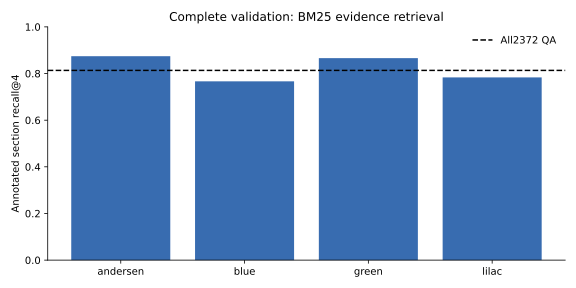

Evidence relevance is separate from answer accuracy and context retention.


In [12]:
recorded_retrieval = read_json("docs/full-validation-retrieval.json")
if (STAGED / "manifest.json").exists():
    validation_stories, validation_questions = load_split(STAGED, "validation")
    cohort = select_validation(validation_questions, policy)
    measured = [
        evidence_metrics(
            [
                validation_stories[q["story"]]["sections"][i]["id"]
                for i in retrieve(
                    q["question"], validation_stories[q["story"]]["sections"]
                )
            ],
            q["gold_sections"],
        )
        for q in cohort
    ]
    actual_recall = sum(r["recall"] for r in measured) / len(measured)
    assert (
        len(measured) == 2372
        and abs(actual_recall - recorded_retrieval["recall_at_4"]) < 1e-12
    )
    print(
        "Recomputed all-query BM25 evidence recall@4:",
        round(actual_recall, 6),
        "n=",
        len(measured),
    )
origins = list(recorded_retrieval["origin"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    [o.replace("-fairybook", "") for o in origins],
    [recorded_retrieval["origin"][o]["recall_at_4"] for o in origins],
    color="#386cb0",
)
ax.axhline(
    recorded_retrieval["recall_at_4"], color="black", linestyle="--", label="All2372 QA"
)
ax.set(
    ylim=(0, 1),
    ylabel="Annotated section recall@4",
    title="Complete validation: BM25 evidence retrieval",
)
ax.legend(frameon=False)
show_figure(fig, "main-validation-evidence")
print("Evidence relevance is separate from answer accuracy and context retention.")


## 4. Generator and resumable optimization

The pinned T5-small model trains on all human-linked training contexts. The
optimizer loop, accumulation, safe checkpoint slots and RNG restoration are
visible below. Epoch snapshots are retained; validation decoding uses complete
hashed shards in a separate phase. Gold sections are not injected at inference.


In [13]:
# Production source: src/resumable_training.py
"""CPU optimizer-boundary checkpoints with exact dropout RNG continuation.

Two alternating slots retain the last committed checkpoint while writing its
successor. Only completed receipts update the pointer. Epoch model snapshots
and measured histories are retained separately by the full-data runner.
"""

import hashlib
import json
import math
import os
from pathlib import Path
import random
import time
import numpy as np
import torch


def file_sha(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, allow_nan=False), encoding="utf-8", newline="\n"
    )
    os.replace(temporary, path)


def rng_state():
    numpy = np.random.get_state()
    return {
        "torch": torch.get_rng_state(),
        "python": random.getstate(),
        "numpy": [
            numpy[0],
            numpy[1].tolist(),
            int(numpy[2]),
            int(numpy[3]),
            float(numpy[4]),
        ],
    }


def restore_rng(value):
    torch.set_rng_state(value["torch"])
    random.setstate(value["python"])
    name, state, position, gaussian, cached = value["numpy"]
    np.random.set_state(
        (name, np.asarray(state, dtype=np.uint32), position, gaussian, cached)
    )


def finite_tensors(value):
    if isinstance(value, torch.Tensor):
        return bool(torch.isfinite(value).all())
    if isinstance(value, dict):
        return all((finite_tensors(v) for v in value.values()))
    if isinstance(value, (list, tuple)):
        return all((finite_tensors(v) for v in value))
    return not isinstance(value, float) or math.isfinite(value)


def save_progress(directory, model, optimizer, identity, progress):
    """Call only after optimizer.step/zero_grad, never mid accumulation."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    pointer = directory / "latest.json"
    previous = (
        json.loads(pointer.read_text(encoding="utf-8")) if pointer.exists() else None
    )
    if previous is not None and (
        previous.get("identity") != identity
        or type(previous.get("slot")) is not int
        or previous["slot"] not in (0, 1)
    ):
        raise ValueError("Refuse to overwrite a different/malformed checkpoint lineage")
    slot = 1 - previous["slot"] if previous else 0
    if any(
        (
            parameter.grad is not None and bool(parameter.grad.ne(0).any())
            for parameter in model.parameters()
        )
    ):
        raise ValueError("Checkpoint must be at an optimizer boundary")
    bundle = {
        "schema": 1,
        "identity": identity,
        "progress": progress,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "rng": rng_state(),
    }
    if not finite_tensors(bundle):
        raise ValueError("Nonfinite checkpoint state")
    path = directory / f"slot-{slot}.pt"
    temporary = path.with_suffix(".pt.tmp")
    torch.save(bundle, temporary)
    os.replace(temporary, path)
    receipt = {
        "schema": 1,
        "slot": slot,
        "state_sha256": file_sha(path),
        "identity": identity,
        "progress": progress,
    }
    atomic_json(directory / f"slot-{slot}.json", receipt)
    atomic_json(pointer, receipt)
    return receipt


def load_progress(directory, model, optimizer, identity):
    directory = Path(directory)
    receipt = json.loads((directory / "latest.json").read_text(encoding="utf-8"))
    if (
        receipt.get("schema") != 1
        or type(receipt.get("slot")) is not int
        or receipt["slot"] not in (0, 1)
    ):
        raise ValueError("Invalid checkpoint pointer")
    if receipt.get("identity") != identity:
        raise ValueError("Resume source/model/policy/runtime identity changed")
    path = directory / f"slot-{receipt['slot']}.pt"
    if file_sha(path) != receipt.get("state_sha256"):
        raise ValueError("Changed resume checkpoint bytes")
    bundle = torch.load(path, map_location="cpu", weights_only=True)
    if (
        not isinstance(bundle, dict)
        or bundle.get("schema") != 1
        or bundle.get("identity") != identity
        or (bundle.get("progress") != receipt.get("progress"))
        or (not finite_tensors(bundle))
    ):
        raise ValueError("Malformed or mismatched resume checkpoint")
    current = optimizer.state_dict()["param_groups"]
    restored = bundle["optimizer"]["param_groups"]
    if len(current) != len(restored) or any(
        (
            {k: v for k, v in a.items() if k != "params"}
            != {k: v for k, v in b.items() if k != "params"}
            for a, b in zip(current, restored)
        )
    ):
        raise ValueError("Resume optimizer configuration changed")
    model.load_state_dict(bundle["model"], strict=True)
    optimizer.load_state_dict(bundle["optimizer"])
    restore_rng(bundle["rng"])
    return bundle["progress"]


def epoch_order(size, seed, epoch):
    """Isolated generator avoids perturbing model/dropout RNG on resume."""
    return torch.randperm(
        size, generator=torch.Generator().manual_seed(seed + epoch)
    ).tolist()


def optimize_epoch(
    model,
    optimizer,
    batches,
    progress,
    accumulation,
    checkpoint,
    *,
    checkpoint_every=128,
    deadline=None,
):
    """Resume only at complete accumulation groups; return False at wall limit.

    Batches are deterministic callables so skipped batches never consume RNG.
    Deadlines stop at a safe boundary and do not remove training examples.
    """
    start = progress["next_microstep"]
    if (
        type(accumulation) is not int
        or accumulation < 1
        or type(start) is not int
        or (not 0 <= start <= len(batches))
    ):
        raise ValueError("Invalid training accumulation/resume position")
    if start != len(batches) and start % accumulation:
        raise ValueError("Resume position is inside an accumulation group")
    if type(checkpoint_every) is not int or checkpoint_every < 1:
        raise ValueError("Invalid checkpoint frequency")
    model.train()
    optimizer.zero_grad(set_to_none=True)
    for index in range(start, len(batches)):
        loss = model(**batches[index]()).loss
        if loss.ndim != 0 or not torch.isfinite(loss):
            raise ValueError("Nonfinite/scalar training loss required")
        progress["loss_sum"] += float(loss.detach())
        group_start = index // accumulation * accumulation
        divisor = min(accumulation, len(batches) - group_start)
        (loss / divisor).backward()
        boundary = (index + 1) % accumulation == 0 or index + 1 == len(batches)
        if boundary:
            if any(
                (
                    not torch.isfinite(p.grad).all()
                    for p in model.parameters()
                    if p.grad is not None
                )
            ):
                raise ValueError("Nonfinite training gradients")
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0, error_if_nonfinite=True
            )
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            progress["next_microstep"] = index + 1
            expired = deadline is not None and time.monotonic() >= deadline
            if (
                expired
                or (index + 1) % checkpoint_every == 0
                or index + 1 == len(batches)
            ):
                checkpoint(dict(progress))
            if expired and index + 1 < len(batches):
                return False
        if (index + 1) % 100 == 0:
            print(
                json.dumps(
                    {
                        "epoch": progress["epoch"],
                        "microstep": index + 1,
                        "mean_train_loss": progress["loss_sum"] / (index + 1),
                    }
                ),
                flush=True,
            )
    return True


# Production source: src/full_generator_training.py
"""Full-cohort T5 training and resumable validation, without test access.

Training keeps every epoch snapshot. Validation decoding is a separate,
shard-resumable phase; a normal cloud time ceiling never becomes a data cap.
"""
import argparse
import importlib.metadata
import json
from pathlib import Path
import platform
import shutil
import time
import torch
from src.data.prepare_fairytale import sha
from src.narrative_training import (
    assemble,
    evaluate,
    load_split,
    seed_all,
    select_validation,
    summarize,
)
from src.resumable_training import (
    atomic_json,
    epoch_order,
    file_sha,
    load_progress,
    optimize_epoch,
    save_progress,
)


def generator_identity(data, protocol, micro_batch, smoke, threads=4):
    policy = json.loads(Path(protocol).read_text(encoding="utf-8"))
    if policy.get("validation_sampling") != {"mode": "all"}:
        raise ValueError("Full-data runner requires uncapped validation")
    if (
        type(micro_batch) is not int
        or micro_batch < 1
        or policy["generator"]["effective_batch_size"] % micro_batch
    ):
        raise ValueError("Microbatch must divide the declared effective batch")
    value = {
        "source_manifest_sha256": file_sha(Path(data) / "manifest.json"),
        "protocol_sha256": file_sha(protocol),
        "micro_batch": micro_batch,
        "smoke": smoke,
        "threads": threads,
        "generator": policy["generator"],
        "torch": str(torch.__version__),
        "python": platform.python_version(),
        "machine": platform.machine(),
        "environment": {
            name: importlib.metadata.version(name)
            for name in ("transformers", "tokenizers", "numpy", "huggingface-hub")
        },
        "source_sha256": {
            name: file_sha(
                Path(str(ROOT / "src/full_generator_training.py")).parent / name
            )
            for name in (
                "full_generator_training.py",
                "resumable_training.py",
                "narrative_training.py",
                "data/prepare_fairytale.py",
            )
        },
        "notebook_source_sha256": notebook_source_sha256(),
    }
    return (policy, value)


def generator_model_loader(checkpoint, revision=None):
    from transformers import AutoModelForSeq2SeqLM

    kwargs = {"use_safetensors": True, "output_loading_info": True}
    if revision is not None:
        kwargs["revision"] = revision
    else:
        kwargs["local_files_only"] = True
    model, loading = AutoModelForSeq2SeqLM.from_pretrained(checkpoint, **kwargs)
    if any(
        (
            loading.get(key)
            for key in (
                "missing_keys",
                "unexpected_keys",
                "mismatched_keys",
                "error_msgs",
            )
        )
    ):
        raise ValueError("Incomplete or mismatched full-generator weights")
    return (model.to("cpu"), loading)


def verify_snapshot(directory, run_identity, epoch):
    directory = Path(directory)
    receipt = json.loads((directory / "receipt.json").read_text(encoding="utf-8"))
    files = receipt.get("files")
    if (
        receipt.get("identity") != run_identity
        or receipt.get("epoch") != epoch
        or (not isinstance(files, dict))
        or (
            not {"model.safetensors", "config.json", "tokenizer_config.json"}.issubset(
                files
            )
        )
    ):
        raise ValueError("Changed preserved epoch identity/files")
    for name, expected in files.items():
        if Path(name).name != name or file_sha(directory / name) != expected:
            raise ValueError("Changed preserved checkpoint weights/config/tokenizer")
    if receipt["weights_sha256"] != files["model.safetensors"]:
        raise ValueError("Conflicting preserved checkpoint weight hash")
    return receipt


def snapshot(output, epoch, model, tokenizer, run_identity, mean_loss=None):
    directory = Path(output) / f"epoch-{epoch}"
    if directory.exists():
        return verify_snapshot(directory, run_identity, epoch)
    directory.mkdir()
    model.save_pretrained(directory, safe_serialization=True)
    tokenizer.save_pretrained(directory)
    receipt = {
        "identity": run_identity,
        "epoch": epoch,
        "mean_train_loss": mean_loss,
        "weights_sha256": file_sha(directory / "model.safetensors"),
        "files": {p.name: file_sha(p) for p in directory.iterdir() if p.is_file()},
    }
    atomic_json(directory / "receipt.json", receipt)
    return receipt


def train_generator_full(
    data,
    protocol,
    output,
    *,
    resume=None,
    micro_batch=2,
    threads=4,
    max_seconds=37800,
    smoke=False,
):
    """Train all declared rows, checkpointing safely before the service ceiling."""
    if (
        type(threads) is not int
        or threads < 1
        or isinstance(max_seconds, bool)
        or (not isinstance(max_seconds, (int, float)))
        or (not 0 <= max_seconds <= 39600)
    ):
        raise ValueError("Positive threads and a safe cloud time window required")
    began = time.monotonic()
    deadline = began + max_seconds
    policy, run_identity = generator_identity(
        data, protocol, micro_batch, smoke, threads
    )
    spec = policy["generator"]
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    seed_all(spec["seed"])
    stories, questions = load_split(data, "train")
    if (
        len(questions)
        != policy["dataset"]["full_coverage"]["custom"]["train"]["QA_metadata"]
    ):
        raise ValueError("Training coverage differs from the full-data protocol")
    if smoke:
        questions = questions[:20]
    output = Path(output)
    if output.exists():
        raise ValueError("Use a fresh run output; resume inputs stay immutable")
    output.mkdir(parents=True)
    if resume is not None:
        resume = Path(resume)
        previous = json.loads((resume / "provenance.json").read_text(encoding="utf-8"))
        if previous["identity"] != run_identity:
            raise ValueError("Resume provenance changed")
        shutil.copytree(resume / "progress", output / "progress")
        for directory in resume.glob("epoch-*"):
            if directory.is_dir():
                verify_snapshot(
                    directory, run_identity, int(directory.name.split("-")[1])
                )
                shutil.copytree(directory, output / directory.name)
    from transformers import AutoTokenizer, DataCollatorForSeq2Seq
    from huggingface_hub import hf_hub_download

    tokenizer = AutoTokenizer.from_pretrained(
        spec["name"], revision=spec["revision"], use_fast=True
    )
    tokenizer.model_max_length = spec["input_tokens"]
    model, loading = generator_model_loader(spec["name"], spec["revision"])
    weights = hf_hub_download(
        spec["name"], "model.safetensors", revision=spec["revision"]
    )
    if (
        file_sha(weights)
        != "bd944e5f1b3ad9b70dd9d00010a517059e19265671076b8b0a4a58d9491842bc"
    ):
        raise ValueError("Full-data protocol's pinned T5-small weight bytes changed")
    atomic_json(
        output / "provenance.json",
        {
            "identity": run_identity,
            "loading_info": loading,
            "pretrained_weights_sha256": file_sha(weights),
            "train_QA": len(questions),
            "train_QA_full": policy["dataset"]["full_coverage"]["custom"]["train"][
                "QA_metadata"
            ],
            "threads": threads,
            "test_accessed": False,
            "smoke": smoke,
        },
    )
    rows = []
    for question in questions:
        story = stories[question["story"]]
        indices = [
            i
            for i, s in enumerate(story["sections"])
            if s["id"] in question["gold_sections"]
        ]
        context, _ = assemble(
            question["question"],
            story["sections"],
            indices,
            tokenizer,
            spec["input_tokens"],
        )
        row = tokenizer(context)
        row["labels"] = tokenizer(
            text_target=question["references"][0],
            max_length=spec["answer_tokens"],
            truncation=True,
        )["input_ids"]
        rows.append(row)
    collator = DataCollatorForSeq2Seq(tokenizer, model=model, padding=True)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=spec["learning_rate"], weight_decay=0.01
    )
    model.gradient_checkpointing_enable()
    model.config.use_cache = False
    progress = {"epoch": 1, "next_microstep": 0, "loss_sum": 0.0}
    if resume is not None:
        progress = load_progress(output / "progress", model, optimizer, run_identity)
    snapshot(output, 0, model, tokenizer, run_identity) if resume is None else None
    epochs = 1 if smoke else spec["epochs"]
    accumulation = spec["effective_batch_size"] // micro_batch
    while progress["epoch"] <= epochs:
        epoch = progress["epoch"]
        order = epoch_order(len(rows), spec["seed"], epoch)
        batches = [
            lambda indices=order[i : i + micro_batch]: collator(
                [rows[j] for j in indices]
            )
            for i in range(0, len(order), micro_batch)
        ]

        def checkpoint(value):
            save_progress(output / "progress", model, optimizer, run_identity, value)

        complete = optimize_epoch(
            model,
            optimizer,
            batches,
            progress,
            accumulation,
            checkpoint,
            deadline=deadline,
        )
        if not complete:
            break
        snapshot(
            output,
            epoch,
            model,
            tokenizer,
            run_identity,
            progress["loss_sum"] / len(batches),
        )
        progress = {"epoch": epoch + 1, "next_microstep": 0, "loss_sum": 0.0}
        checkpoint(progress)
        if time.monotonic() >= deadline:
            break
    status = {
        "status": "training_complete" if progress["epoch"] > epochs else "checkpointed",
        "progress": progress,
        "epochs_required": epochs,
        "all_training_QA": len(questions),
        "seconds": time.monotonic() - began,
        "test_accessed": False,
        "smoke": smoke,
    }
    atomic_json(output / "training-status.json", status)
    print(json.dumps(status), flush=True)
    return status


def validate_generator_epoch(
    data,
    protocol,
    run,
    epoch,
    output,
    *,
    previous=None,
    micro_batch=2,
    threads=4,
    max_seconds=37800,
    smoke=False,
    shard_size=64,
):
    """Decode every validation query, resuming only complete hashed shards."""
    if (
        type(epoch) is not int
        or epoch < 0
        or type(shard_size) is not int
        or (shard_size < 1)
        or (type(threads) is not int)
        or (threads < 1)
        or isinstance(max_seconds, bool)
        or (not isinstance(max_seconds, (int, float)))
        or (not 0 <= max_seconds <= 39600)
    ):
        raise ValueError("Valid epoch and positive shard size required")
    policy, run_identity = generator_identity(
        data, protocol, micro_batch, smoke, threads
    )
    run, output = (Path(run), Path(output))
    snapshot_path = run / f"epoch-{epoch}"
    receipt = verify_snapshot(snapshot_path, run_identity, epoch)
    stories, questions = load_split(data, "validation")
    questions = select_validation(questions, policy)
    if (
        len(questions)
        != policy["dataset"]["full_coverage"]["custom"]["validation"]["QA_metadata"]
    ):
        raise ValueError("Validation coverage differs from full-data protocol")
    if smoke:
        questions = questions[:2]
    validation_identity = {
        "run": run_identity,
        "epoch": epoch,
        "weights_sha256": receipt["weights_sha256"],
        "validation_ids_sha256": sha(json.dumps([q["id"] for q in questions]).encode()),
        "shard_size": shard_size,
    }
    if output.exists():
        raise ValueError("Use a fresh validation output; preserve prior shards")
    output.mkdir(parents=True)
    if previous is not None:
        previous = Path(previous)
        if (
            json.loads((previous / "identity.json").read_text(encoding="utf-8"))
            != validation_identity
        ):
            raise ValueError("Changed validation resume identity")
        for path in previous.glob("shard-*.json"):
            shutil.copy2(path, output / path.name)
    atomic_json(output / "identity.json", validation_identity)
    from transformers import AutoTokenizer

    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    tokenizer = AutoTokenizer.from_pretrained(
        snapshot_path, local_files_only=True, use_fast=True
    )
    tokenizer.model_max_length = policy["generator"]["input_tokens"]
    model, loading = generator_model_loader(snapshot_path)
    deadline = time.monotonic() + max_seconds
    combined = []
    for start in range(0, len(questions), shard_size):
        path = output / f"shard-{start:05d}.json"
        expected_ids = [q["id"] for q in questions[start : start + shard_size]]
        if path.exists():
            shard = json.loads(path.read_text(encoding="utf-8"))
            if (
                shard.get("identity") != validation_identity
                or [r["id"] for r in shard["predictions"]] != expected_ids
                or sha(
                    json.dumps(
                        shard["predictions"], sort_keys=True, allow_nan=False
                    ).encode()
                )
                != shard.get("predictions_sha256")
            ):
                raise ValueError("Changed validation shard")
        else:
            predictions, _ = evaluate(
                model, tokenizer, stories, questions[start : start + shard_size]
            )
            shard = {
                "identity": validation_identity,
                "predictions": predictions,
                "predictions_sha256": sha(
                    json.dumps(predictions, sort_keys=True, allow_nan=False).encode()
                ),
            }
            atomic_json(path, shard)
        combined.extend(shard["predictions"])
        print(
            json.dumps(
                {
                    "epoch": epoch,
                    "validation_QA_completed": len(combined),
                    "required": len(questions),
                }
            ),
            flush=True,
        )
        if time.monotonic() >= deadline:
            break
    complete = len(combined) == len(questions)
    status = {
        "complete": complete,
        "questions_completed": len(combined),
        "questions_required": len(questions),
        "identity": validation_identity,
        "loading_info": loading,
        "test_accessed": False,
        "smoke": smoke,
    }
    if complete:
        status["validation"] = summarize(combined)
    atomic_json(output / "validation-status.json", status)
    return status


epoch,mean training loss,weights SHA256
1,1.1786895456597708,6752700e682cf3f25f4c50eef2ac44b7d8c186fe3497632fae97b264c9d819ac
2,0.9940754068993648,4b94b6c580d1aa182b7b04cbeede8f3430bc1b019709266637f973b51137d227
3,0.9059641202162801,4a51a48953e6c02c2c8aa5325a02600ae7a65dc8080abb5fb45e2b7131c39538


Actual training seconds: 27129.262157562
Training-status receipt: ea131acfc1aa1f515b9bdff386aa63ab45d633f6d8bbf9a5c0eea90d4dc4709a


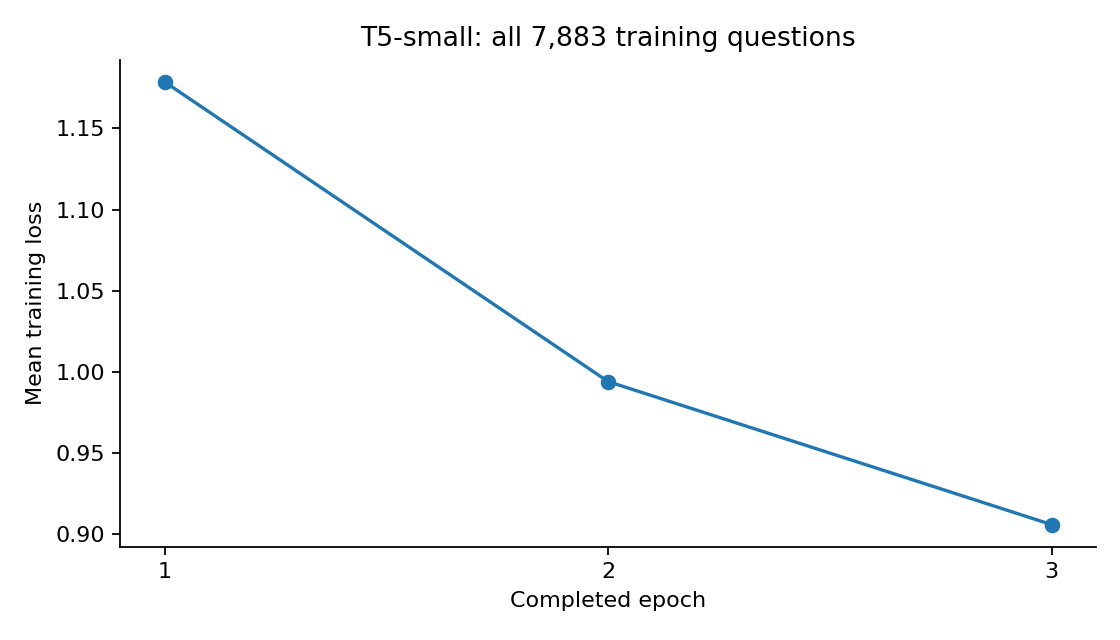

In [14]:
training = read_json("docs/full-generator-training.json")
assert training["training_complete"] is True and training["training_questions"] == 7883
assert training["epochs_required"] == 3 and training["test_accessed"] is False
table(
    [{"epoch": row["epoch"], "mean training loss": row["mean_train_loss"],
      "weights SHA256": row["weights_sha256"]} for row in training["checkpoints"] if row["epoch"] > 0],
    ["epoch", "mean training loss", "weights SHA256"],
    "Measured full training: all 7,883 questions in each of three epochs",
)
print("Actual training seconds:", training["seconds"])
print("Training-status receipt:", training["training_status_sha256"])
from IPython.display import Image, display
display(Image(filename=str(ROOT / "assets/plots/full-generator-training-loss.png")))
if RUN_TRAIN:
    train_generator_full(STAGED, PROTOCOL, RUN_DIR)


## 5. Evidence-supervised listwise ranking

Every annotated positive forms a group with nongold same-story hard negatives.
The scalar pretrained head, listwise loss, optimizer continuation and complete
validation are visible below. Annotation omissions can make valid evidence an
imperfect negative. Questions without a negative stay in the QA coverage count.


In [15]:
# Production source: src/reranker_training.py
import argparse
import json
from pathlib import Path
import random
import time
from src.data.prepare_fairytale import sha
from src.narrative_training import (
    evidence_metrics,
    lexical_ranking,
    load_split,
    retrieve,
    seed_all,
    select_validation,
)


def build_groups(stories, questions, seed=42):
    groups = []
    skipped = 0
    for question in questions:
        sections = stories[question["story"]]["sections"]
        gold = set(question["gold_sections"])
        order = lexical_ranking(question["question"], sections)
        negatives = [i for i in order if sections[i]["id"] not in gold]
        if not negatives:
            skipped += 1
            continue
        chosen = negatives[:3]
        rest = negatives[3:]
        if rest:
            rng = random.Random(seed + int(sha(question["id"].encode())[:12], 16))
            chosen.append(rng.choice(rest))
        for positive, section in enumerate(sections):
            if section["id"] in gold:
                indices = [positive] + chosen
                groups.append(
                    {
                        "id": question["id"],
                        "positive_section": section["id"],
                        "section_ids": [sections[i]["id"] for i in indices],
                        "pairs": [
                            (question["question"], sections[i]["text"]) for i in indices
                        ],
                    }
                )
    return (groups, skipped)


class SectionReranker:

    def __init__(self, model, tokenizer, max_tokens=384, batch_size=8):
        if (
            type(max_tokens) is not int
            or max_tokens < 16
            or type(batch_size) is not int
            or (batch_size < 1)
        ):
            raise ValueError(
                "Positive ranking batch size and context capacity required"
            )
        self.model = model
        self.tokenizer = tokenizer
        self.max_tokens = max_tokens
        self.batch_size = batch_size

    def predict(self, pairs, **unused):
        import numpy as np
        import torch

        self.model.eval()
        scores = []
        if any(
            (
                len(self.tokenizer.encode(p[0], add_special_tokens=False))
                > self.max_tokens - 8
                for p in pairs
            )
        ):
            raise ValueError("Question exceeds ranking token capacity")
        for start in range(0, len(pairs), self.batch_size):
            batch = pairs[start : start + self.batch_size]
            encoded = self.tokenizer(
                [p[0] for p in batch],
                [p[1] for p in batch],
                max_length=self.max_tokens,
                padding=True,
                truncation="only_second",
                return_tensors="pt",
            ).to(self.model.device)
            with torch.inference_mode():
                logits = self.model(**encoded).logits[:, 0]
            if not torch.isfinite(logits).all():
                raise ValueError("Nonfinite section-reranker logits")
            scores.extend(logits.cpu().tolist())
        return np.asarray(scores)


def evaluate_sections(stories, questions, reranker=None, cases_path=None):
    rows = []
    for question in questions:
        sections = stories[question["story"]]["sections"]
        indices = retrieve(question["question"], sections, reranker)
        selected = [sections[i]["id"] for i in indices]
        candidates = [
            sections[i]["id"]
            for i in lexical_ranking(question["question"], sections)[:12]
        ]
        metrics = evidence_metrics(selected, question["gold_sections"])
        rows.append(
            {
                "id": question["id"],
                "story": question["story"],
                "selected_sections": selected,
                "gold_sections": question["gold_sections"],
                "candidate_sections": candidates,
                "origin": question["origin"],
                "attribute": question["attribute"],
                "explicit": question["explicit"],
                **metrics,
                "candidate_recall": evidence_metrics(
                    candidates, question["gold_sections"]
                )["recall"],
                "top4_ceiling": min(4, len(question["gold_sections"]))
                / len(question["gold_sections"]),
            }
        )
    report = {
        "n": len(rows),
        "recall_at_4": sum((r["recall"] for r in rows)) / len(rows),
        "precision_at_4": sum((r["precision"] for r in rows)) / len(rows),
        "candidate_recall_at_12": sum((r["candidate_recall"] for r in rows))
        / len(rows),
        "annotation_top4_ceiling": sum((r["top4_ceiling"] for r in rows)) / len(rows),
    }
    for group in ("origin", "attribute", "explicit"):
        report[group] = {
            value: {
                "n": sum((r[group] == value for r in rows)),
                "recall_at_4": sum((r["recall"] for r in rows if r[group] == value))
                / sum((r[group] == value for r in rows)),
            }
            for value in sorted(set((r[group] for r in rows)))
        }
    if cases_path is not None:
        with Path(cases_path).open("x", encoding="utf-8") as handle:
            json.dump(rows, handle)
    return report


# Production source: src/full_reranker_training.py
"""Uncapped evidence ranking with optimizer continuation and hashed validation shards."""
import argparse
import importlib.metadata
import json
from pathlib import Path
import platform
import shutil
import time
from types import SimpleNamespace
import torch
from src.data.prepare_fairytale import sha
from src.full_generator_training import snapshot, verify_snapshot
from src.narrative_training import load_split, seed_all, select_validation
from src.reranker_training import SectionReranker, build_groups, evaluate_sections
from src.resumable_training import (
    atomic_json,
    epoch_order,
    file_sha,
    load_progress,
    optimize_epoch,
    save_progress,
)


class ListwiseRanker(torch.nn.Module):
    """Train the pretrained scalar head; every group starts with its positive."""

    def __init__(self, ranker):
        super().__init__()
        self.ranker = ranker

    def forward(self, counts, **encoded):
        if not counts or any((type(count) is not int or count < 2 for count in counts)):
            raise ValueError("Each listwise group needs a positive and negative")
        logits = self.ranker(**encoded).logits[:, 0]
        if not torch.isfinite(logits).all() or sum(counts) != len(logits):
            raise ValueError("Invalid listwise logits/group geometry")
        losses, offset = ([], 0)
        for count in counts:
            if type(count) is not int or count < 2:
                raise ValueError("Each listwise group needs a positive and negative")
            losses.append(-torch.log_softmax(logits[offset : offset + count], dim=0)[0])
            offset += count
        return SimpleNamespace(loss=torch.stack(losses).mean())


def ranking_identity(data, protocol, smoke, threads):
    policy = json.loads(Path(protocol).read_text(encoding="utf-8"))
    training = policy["training"]
    if policy.get("validation_sampling") != {"mode": "all"}:
        raise ValueError("Full ranking requires all validation questions")
    if (
        file_sha(Path(data) / "manifest.json")
        != policy["source"]["dataset_manifest_sha256"]
    ):
        raise ValueError("Changed full source manifest")
    if (
        type(threads) is not int
        or threads < 1
        or any(
            (
                type(training[k]) is not int or training[k] < 1
                for k in ("micro_groups", "effective_groups", "epochs")
            )
        )
        or training["effective_groups"] % training["micro_groups"]
    ):
        raise ValueError("Invalid group accumulation/thread configuration")
    value = {
        "manifest_sha256": file_sha(Path(data) / "manifest.json"),
        "protocol_sha256": file_sha(protocol),
        "model": policy["model"],
        "training": training,
        "smoke": smoke,
        "threads": threads,
        "torch": str(torch.__version__),
        "python": platform.python_version(),
        "environment": {
            n: importlib.metadata.version(n)
            for n in ("transformers", "tokenizers", "numpy", "huggingface-hub")
        },
        "source_sha256": {
            n: file_sha(Path(str(ROOT / "src/full_reranker_training.py")).parent / n)
            for n in (
                "full_reranker_training.py",
                "reranker_training.py",
                "resumable_training.py",
                "full_generator_training.py",
                "narrative_training.py",
                "data/prepare_fairytale.py",
            )
        },
        "notebook_source_sha256": notebook_source_sha256(),
    }
    return (policy, value)


def ranking_model_loader(path, revision=None):
    from transformers import AutoModelForSequenceClassification

    kwargs = {"use_safetensors": True, "output_loading_info": True}
    kwargs.update({"revision": revision} if revision else {"local_files_only": True})
    model, info = AutoModelForSequenceClassification.from_pretrained(path, **kwargs)
    if (
        any(
            (
                info.get(k)
                for k in (
                    "missing_keys",
                    "unexpected_keys",
                    "mismatched_keys",
                    "error_msgs",
                )
            )
        )
        or model.config.num_labels != 1
    ):
        raise ValueError("Incomplete pretrained scalar ranking head")
    return (model.to("cpu"), info)


def train_ranking_full(
    data, protocol, output, *, resume=None, smoke=False, threads=4, max_seconds=37800
):
    if (
        isinstance(max_seconds, bool)
        or not isinstance(max_seconds, (int, float))
        or (not 0 <= max_seconds <= 39600)
    ):
        raise ValueError("Safe cloud checkpoint window required")
    began = time.monotonic()
    deadline = began + max_seconds
    policy, lineage = ranking_identity(data, protocol, smoke, threads)
    spec, training = (policy["model"], policy["training"])
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    seed_all(spec["seed"])
    stories, questions = load_split(data, "train")
    if len(questions) != 7883:
        raise ValueError("Expected all 7883 source-family training questions")
    if smoke:
        questions = questions[:20]
    groups, skipped = build_groups(stories, questions, spec["seed"])
    if not groups:
        raise ValueError("No supervised ranking groups")
    output = Path(output)
    if output.exists():
        raise ValueError("Preserve prior outputs; resume into a fresh directory")
    output.mkdir(parents=True)
    if resume is not None:
        resume = Path(resume)
        if json.loads((resume / "provenance.json").read_text())["identity"] != lineage:
            raise ValueError("Changed ranking resume identity")
        shutil.copytree(resume / "progress", output / "progress")
        for p in resume.glob("epoch-*"):
            verify_snapshot(p, lineage, int(p.name.split("-")[1]))
            shutil.copytree(p, output / p.name)
    from transformers import AutoTokenizer
    from huggingface_hub import hf_hub_download

    tokenizer = AutoTokenizer.from_pretrained(
        spec["name"], revision=spec["revision"], use_fast=True
    )
    model, loading = ranking_model_loader(spec["name"], spec["revision"])
    weights = hf_hub_download(
        spec["name"], "model.safetensors", revision=spec["revision"]
    )
    if (
        file_sha(weights)
        != "821d1aa69520101d6e0737f78a042ae25b19e5cb9160701909d10434f4aeb0ae"
    ):
        raise ValueError("Pinned pretrained ranking weight bytes changed")
    encoded_groups, truncated = ([], 0)
    print(json.dumps({"phase": "tokenizing", "groups": len(groups)}), flush=True)
    for group in groups:
        pairs = group["pairs"]
        if any(
            (
                len(tokenizer.encode(q, add_special_tokens=False))
                > spec["max_tokens"] - 8
                for q, _ in pairs
            )
        ):
            raise ValueError("Training question exceeds pair token capacity")
        lengths = tokenizer(
            [q for q, _ in pairs], [s for _, s in pairs], truncation=False
        )["input_ids"]
        truncated += sum((len(row) > spec["max_tokens"] for row in lengths))
        encoded_groups.append(
            tokenizer(
                [q for q, _ in pairs],
                [s for _, s in pairs],
                truncation="only_second",
                max_length=spec["max_tokens"],
            )
        )
    atomic_json(
        output / "provenance.json",
        {
            "identity": lineage,
            "loading_info": loading,
            "pretrained_weights_sha256": file_sha(weights),
            "train_QA": len(questions),
            "groups": len(groups),
            "pairs": sum((len(g["pairs"]) for g in groups)),
            "questions_without_negatives": skipped,
            "truncated_pairs": truncated,
            "test_accessed": False,
        },
    )
    wrapper = ListwiseRanker(model)
    model.gradient_checkpointing_enable()
    optimizer = torch.optim.AdamW(
        wrapper.parameters(),
        lr=training["learning_rate"],
        weight_decay=training["weight_decay"],
    )
    progress = {"epoch": 1, "next_microstep": 0, "loss_sum": 0.0}
    if resume is not None:
        progress = load_progress(output / "progress", wrapper, optimizer, lineage)
    else:
        snapshot(output, 0, model, tokenizer, lineage)
        seed_all(spec["seed"])
    micro = training["micro_groups"]

    def batch(indices):
        rows = []
        for i in indices:
            encoded = encoded_groups[i]
            rows.extend(
                (
                    {k: v[j] for k, v in encoded.items()}
                    for j in range(len(encoded["input_ids"]))
                )
            )
        return {
            **tokenizer.pad(rows, padding=True, return_tensors="pt"),
            "counts": [len(groups[i]["pairs"]) for i in indices],
        }

    epochs = 1 if smoke else training["epochs"]
    while progress["epoch"] <= epochs:
        epoch = progress["epoch"]
        order = epoch_order(len(groups), spec["seed"], epoch)
        batches = [
            lambda ids=order[i : i + micro]: batch(ids)
            for i in range(0, len(order), micro)
        ]

        def checkpoint(value):
            save_progress(output / "progress", wrapper, optimizer, lineage, value)

        if not optimize_epoch(
            wrapper,
            optimizer,
            batches,
            progress,
            training["effective_groups"] // micro,
            checkpoint,
            deadline=deadline,
        ):
            break
        snapshot(
            output,
            epoch,
            model,
            tokenizer,
            lineage,
            progress["loss_sum"] / len(batches),
        )
        progress = {"epoch": epoch + 1, "next_microstep": 0, "loss_sum": 0.0}
        checkpoint(progress)
        if time.monotonic() >= deadline:
            break
    status = {
        "status": "training_complete" if progress["epoch"] > epochs else "checkpointed",
        "progress": progress,
        "epochs_required": epochs,
        "train_QA": len(questions),
        "seconds": time.monotonic() - began,
        "smoke": smoke,
        "test_accessed": False,
    }
    atomic_json(output / "training-status.json", status)
    return status


def summarize_rows(rows):
    if not rows:
        raise ValueError("Cannot summarize empty validation")

    def metrics(items):
        return {
            "n": len(items),
            **{
                key: sum((r[field] for r in items)) / len(items)
                for key, field in (
                    ("recall_at_4", "recall"),
                    ("precision_at_4", "precision"),
                    ("candidate_recall_at_12", "candidate_recall"),
                    ("annotation_top4_ceiling", "top4_ceiling"),
                )
            },
        }

    result = metrics(rows)
    for key in ("origin", "attribute", "explicit"):
        result[key] = {
            v: metrics([r for r in rows if r[key] == v])
            for v in sorted({r[key] for r in rows})
        }
    return result


def validate_ranking_epoch(
    data,
    protocol,
    run,
    epoch,
    output,
    *,
    previous=None,
    smoke=False,
    threads=4,
    max_seconds=37800,
    shard_size=64,
):
    if (
        type(epoch) is not int
        or not 0 <= epoch <= 2
        or type(shard_size) is not int
        or (shard_size < 1)
        or isinstance(max_seconds, bool)
        or (not isinstance(max_seconds, (int, float)))
        or (not 0 <= max_seconds <= 39600)
    ):
        raise ValueError("Valid snapshot, shard size and cloud window required")
    policy, lineage = ranking_identity(data, protocol, smoke, threads)
    stories, questions = load_split(data, "validation")
    questions = select_validation(questions, policy)
    if (
        len(questions) != 2372
        or sha(json.dumps([q["id"] for q in questions]).encode())
        != policy["source"]["validation_ids_sha256"]
    ):
        raise ValueError("Changed full validation coverage")
    if smoke:
        questions = questions[:2]
    checkpoint = Path(run) / f"epoch-{epoch}"
    receipt = verify_snapshot(checkpoint, lineage, epoch)
    cohort = {
        "run": lineage,
        "epoch": epoch,
        "weights_sha256": receipt["weights_sha256"],
        "ids_sha256": sha(json.dumps([q["id"] for q in questions]).encode()),
        "shard_size": shard_size,
    }
    output = Path(output)
    if output.exists():
        raise ValueError("Preserve prior validation shards")
    output.mkdir(parents=True)
    if previous is not None:
        previous = Path(previous)
        if json.loads((previous / "identity.json").read_text()) != cohort:
            raise ValueError("Changed validation continuation identity")
        for path in previous.glob("shard-*.json"):
            shutil.copy2(path, output / path.name)
    atomic_json(output / "identity.json", cohort)
    from transformers import AutoTokenizer

    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    tokenizer = AutoTokenizer.from_pretrained(
        checkpoint, local_files_only=True, use_fast=True
    )
    model, loading = ranking_model_loader(checkpoint)
    scorer = SectionReranker(model, tokenizer, policy["model"]["max_tokens"])
    combined = []
    deadline = time.monotonic() + max_seconds
    for start in range(0, len(questions), shard_size):
        path = output / f"shard-{start:05d}.json"
        expected = [q["id"] for q in questions[start : start + shard_size]]
        if path.exists():
            shard = json.loads(path.read_text())
            if (
                shard.get("identity") != cohort
                or [r["id"] for r in shard["rows"]] != expected
                or sha(
                    json.dumps(shard["rows"], sort_keys=True, allow_nan=False).encode()
                )
                != shard.get("rows_sha256")
            ):
                raise ValueError("Changed validation shard")
        else:
            private = output / "pending-cases.json"
            evaluate_sections(
                stories, questions[start : start + shard_size], scorer, private
            )
            rows = json.loads(private.read_text())
            private.unlink()
            shard = {
                "identity": cohort,
                "rows": rows,
                "rows_sha256": sha(
                    json.dumps(rows, sort_keys=True, allow_nan=False).encode()
                ),
            }
            atomic_json(path, shard)
        combined.extend(shard["rows"])
        print(
            json.dumps(
                {"validation_QA_completed": len(combined), "required": len(questions)}
            ),
            flush=True,
        )
        if time.monotonic() >= deadline:
            break
    complete = len(combined) == len(questions)
    status = {
        "complete": complete,
        "questions_completed": len(combined),
        "questions_required": len(questions),
        "identity": cohort,
        "loading_info": loading,
        "test_accessed": False,
        "smoke": smoke,
    }
    if complete:
        status["validation"] = summarize_rows(combined)
        status["bm25"] = evaluate_sections(stories, questions)
    atomic_json(output / "validation-status.json", status)
    return status


In [16]:
r = read_json("docs/ranking-supervision.json")
table(
    [
        {
            k: r[k]
            for k in [
                "train_questions",
                "training_groups",
                "training_pairs",
                "questions_without_nongold_negative",
                "test_accessed",
            ]
        }
    ],
    [
        "train_questions",
        "training_groups",
        "training_pairs",
        "questions_without_nongold_negative",
        "test_accessed",
    ],
    "Actually constructed full-cohort training supervision",
)
proof = read_json("docs/full-reranker-readiness.json")
print(
    "Actual equal state tensors:",
    proof["equal_training_state_tensor_counts"],
    "all RNG states equal:",
    proof["all_rng_states_equal"],
)
print("Validation-shard continuation exact:", proof["validation_shard_replay_exact"])
if RUN_RERANKER_TRAIN:
    train_ranking_full(
        STAGED,
        ROOT / "docs/full-reranker-protocol.json",
        RUN_DIR.with_name(RUN_DIR.name + "-ranking"),
    )


train_questions,training_groups,training_pairs,questions_without_nongold_negative,test_accessed
7883,8848,43757,3,False


Actual equal state tensors: {'model': 105, 'optimizer': 315, 'rng': 1} all RNG states equal: True
Validation-shard continuation exact: True


## 6. Extractive answers and source auditing

The operational extractive reader returns a literal source span. Generated text
is a separate answer type and must not be labelled a verbatim span. Exact source
offsets and frozen policy/model contracts are checked without claiming entailment.


In [17]:
def validate_loading_info(info):
    if any(info.get(key) for key in ("missing_keys", "mismatched_keys", "error_msgs")):
        raise ValueError(
            "Pretrained QA checkpoint has missing, mismatched or erroneous parameters"
        )
    expected_unused = {"bert.pooler.dense.weight", "bert.pooler.dense.bias"}
    if set(info.get("unexpected_keys", [])) - expected_unused:
        raise ValueError("Unexpected pretrained checkpoint parameters")


In [18]:
@lru_cache(maxsize=1)
def reader():
    import torch
    from transformers import AutoTokenizer, AutoModelForQuestionAnswering

    torch.set_num_threads(2)
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL, revision=REVISION, trust_remote_code=False
    )
    model, loading_info = AutoModelForQuestionAnswering.from_pretrained(
        MODEL,
        revision=REVISION,
        trust_remote_code=False,
        use_safetensors=True,
        output_loading_info=True,
    )
    validate_loading_info(loading_info)
    model.eval()
    return tokenizer, model


def candidates(
    question, passages, sliding=False, max_length=384, stride=96, batch_size=8
):
    import torch

    if not passages:
        return []
    if not isinstance(question, str) or not question.strip():
        return []
    if (
        not 128 <= max_length <= 512
        or not 0 <= stride < max_length // 2
        or batch_size < 1
    ):
        raise ValueError("Invalid reader window or batch configuration")
    tokenizer, model = reader()
    if len(tokenizer.encode(question, add_special_tokens=False)) > max_length - 32:
        return []
    options = {"return_overflowing_tokens": True, "stride": stride} if sliding else {}
    encoded = tokenizer(
        [question] * len(passages),
        [p.text for p in passages],
        padding=True,
        truncation="only_second",
        max_length=max_length,
        return_offsets_mapping=True,
        return_tensors="pt",
        **options
    )
    mapping = (
        encoded.pop("overflow_to_sample_mapping").tolist()
        if sliding
        else list(range(len(passages)))
    )
    offsets = encoded.pop("offset_mapping").tolist()
    starts_all = []
    ends_all = []
    for lo in range(0, len(mapping), batch_size):
        batch = {key: value[lo : lo + batch_size] for key, value in encoded.items()}
        with torch.inference_mode():
            output = model(**batch)
        starts_all.extend(output.start_logits)
        ends_all.extend(output.end_logits)
    result = []
    for row, passage_id in enumerate(mapping):
        p = passages[passage_id]
        context = [
            i
            for i, seq in enumerate(encoded.sequence_ids(row))
            if seq == 1 and offsets[row][i][1] > offsets[row][i][0]
        ]
        if not context:
            continue
        starts = starts_all[row]
        ends = ends_all[row]
        if not torch.isfinite(starts).all() or not torch.isfinite(ends).all():
            continue
        top_starts = sorted(context, key=lambda i: -float(starts[i]))[:20]
        top_ends = sorted(context, key=lambda i: -float(ends[i]))[:20]
        valid = [
            (float(starts[a] + ends[b]), a, b)
            for a in top_starts
            for b in top_ends
            if a <= b < a + 30
        ]
        if not valid:
            continue
        score, a, b = max(valid)
        cls = (encoded["input_ids"][row] == tokenizer.cls_token_id).nonzero()[0].item()
        margin = score - float(starts[cls] + ends[cls])
        start, end = offsets[row][a][0], offsets[row][b][1]
        result.append(
            {
                "answer": p.text[start:end],
                "citation": p.id,
                "book": p.book,
                "answer_start": p.start + start,
                "answer_end": p.start + end,
                "null_margin": margin,
                "reader_window": row,
                "retrieval_rank": passage_id + 1,
            }
        )
    return sorted(result, key=lambda r: -r["null_margin"])


In [19]:
def expand_passage(passage, text, characters=700):
    if not isinstance(characters, int) or characters < 0:
        raise ValueError("Expansion must be a nonnegative integer")
    if text[passage.start : passage.end] != passage.text:
        raise ValueError("Cannot expand a passage that mismatches its source")
    start = max(0, passage.start - characters)
    end = min(len(text), passage.end + characters)
    # Avoid cutting words while retaining exact source coordinates.
    while start > 0 and not text[start - 1].isspace():
        start -= 1
    while end < len(text) and not text[end].isspace():
        end += 1
    return Passage(
        f"{passage.book}:{start}-{end}",
        passage.book,
        start,
        end,
        text[start:end],
        passage.progress,
    )


def select_span(spans, threshold=0, rank_penalty=0):
    if (
        not math.isfinite(threshold)
        or not math.isfinite(rank_penalty)
        or rank_penalty < 0
    ):
        raise ValueError("Threshold and nonnegative rank penalty must be finite")
    eligible = [
        s
        for s in spans
        if math.isfinite(s["null_margin"])
        and s["null_margin"] > threshold
        and isinstance(s.get("retrieval_rank", 1), int)
        and s.get("retrieval_rank", 1) >= 1
    ]
    if not eligible:
        return None
    return max(
        eligible,
        key=lambda s: s["null_margin"]
        - rank_penalty * (s.get("retrieval_rank", 1) - 1),
    )


def assemble_span_answer(span, passages, book):
    if span is None:
        return {
            "abstained": True,
            "answer": None,
            "reason": "No span exceeded the frozen null threshold",
        }
    known = {p.id: p for p in passages}
    passage = known.get(span["citation"])
    if passage is None or passage.book != book or span.get("book") != book:
        return {
            "abstained": True,
            "answer": None,
            "reason": "Span source is absent or belongs to another book",
        }
    start = span["answer_start"] - passage.start
    end = span["answer_end"] - passage.start
    if (
        not 0 <= start < end <= len(passage.text)
        or passage.text[start:end] != span["answer"]
    ):
        return {
            "abstained": True,
            "answer": None,
            "reason": "Answer does not exactly match cited source coordinates",
        }
    return {
        **span,
        "abstained": False,
        "evidence": {
            "citation": passage.id,
            "answer_start": span["answer_start"],
            "answer_end": span["answer_end"],
        },
        "citation_method": "Deterministically assembled from exact source offsets; no model-generated quote JSON",
        "semantic_correctness_verified": False,
    }


In [20]:
def finite_number(value):
    if type(value) not in (int, float):
        return False
    try:
        return math.isfinite(value)
    except OverflowError:
        return False


def digest_policy(policy):
    raw = json.dumps(
        policy,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False,
        allow_nan=False,
    ).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


def policy_from_selection(selection):
    if (
        not isinstance(selection, dict)
        or not isinstance(selection.get("selected"), dict)
        or not isinstance(selection.get("models"), dict)
    ):
        raise ValueError(
            "Frozen selection must contain models and selected policy objects"
        )
    selected = selection["selected"]
    if not {"config", "threshold", "rank_penalty"} <= set(selected):
        raise ValueError("Frozen selection is missing required policy fields")
    policy = {
        "models": selection["models"],
        "config": selected["config"],
        "threshold": selected["threshold"],
        "rank_penalty": selected["rank_penalty"],
    }
    validate_policy(policy)
    return policy


def validate_policy(policy):
    if not isinstance(policy, dict) or not {
        "models",
        "config",
        "threshold",
        "rank_penalty",
    } <= set(policy):
        raise ValueError("Answer policy must contain required policy fields")
    if (
        not finite_number(policy["threshold"])
        or not finite_number(policy["rank_penalty"])
        or policy["rank_penalty"] < 0
    ):
        raise ValueError("Invalid finite selection parameters")
    config = policy["config"]
    if not isinstance(config, dict) or not {
        "words",
        "overlap",
        "k",
        "expand",
        "sliding",
    } <= set(config):
        raise ValueError("Answer policy has incomplete chunk configuration")
    if (
        type(config["words"]) is not int
        or type(config["overlap"]) is not int
        or not 0 <= config["overlap"] < config["words"]
        or type(config["k"]) is not int
        or config["k"] < 1
        or type(config["expand"]) is not int
        or config["expand"] < 0
        or type(config["sliding"]) is not bool
    ):
        raise ValueError("Invalid persisted chunk or reader configuration")
    models = policy["models"]
    if (
        not isinstance(models, dict)
        or not isinstance(models.get("reader"), str)
        or not models["reader"]
        or any(
            not isinstance(models.get(key), str)
            or not re.fullmatch(r"[0-9a-f]{40}", models[key])
            for key in ("embedding_revision", "reader_revision", "reranker_revision")
        )
    ):
        raise ValueError("Missing exact persisted model revisions")


def verify_artifact(artifact, text, expected_selection=None):
    if not isinstance(artifact, dict):
        raise ValueError("Answer artifact must be an object")
    if not isinstance(text, str):
        raise ValueError("Source must be Unicode text")
    if not {"policy", "policy_sha256", "source_sha256", "book", "abstained"} <= set(
        artifact
    ):
        raise ValueError("Answer artifact is missing required fields")
    if (
        type(artifact.get("artifact_schema")) is not int
        or artifact["artifact_schema"] != 1
    ):
        raise ValueError("Unsupported answer artifact schema")
    book = artifact.get("book")
    if not isinstance(book, str) or not re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9_-]*", book
    ):
        raise ValueError("Invalid source book identifier")
    if (
        artifact.get("source_sha256")
        != hashlib.sha256(text.encode("utf-8")).hexdigest()
    ):
        raise ValueError("Answer source fingerprint changed")
    policy = artifact["policy"]
    validate_policy(policy)
    if artifact.get("policy_sha256") != digest_policy(policy):
        raise ValueError("Answer policy fingerprint changed")
    if expected_selection is not None and policy != policy_from_selection(
        expected_selection
    ):
        raise ValueError("Artifact differs from the expected frozen selection")
    config = policy["config"]
    if type(artifact.get("abstained")) is not bool:
        raise ValueError("Abstention status must be explicit")
    if artifact["abstained"]:
        if artifact.get("answer") is not None or any(
            key in artifact for key in ("citation", "answer_start", "answer_end")
        ):
            raise ValueError("Abstention cannot carry an accepted answer")
        return {
            "valid": True,
            "abstained": True,
            "source_exact": None,
            "frozen_policy_matches": expected_selection is not None,
            "semantic_correctness_verified": False,
            "authenticity_verified": False,
        }
    answer, start, end = (
        artifact.get("answer"),
        artifact.get("answer_start"),
        artifact.get("answer_end"),
    )
    citation = artifact.get("citation")
    match = (
        re.fullmatch(r"([A-Za-z0-9][A-Za-z0-9_-]*):(\d+)-(\d+)", citation)
        if isinstance(citation, str)
        else None
    )
    if (
        not match
        or match[1] != book
        or type(start) is not int
        or type(end) is not int
        or not 0 <= int(match[2]) <= start < end <= int(match[3]) <= len(text)
        or not isinstance(answer, str)
        or text[start:end] != answer
    ):
        raise ValueError("Answer does not match cited source coordinates")
    if (
        not finite_number(artifact.get("null_margin"))
        or artifact["null_margin"] <= policy["threshold"]
        or type(artifact.get("retrieval_rank")) is not int
        or not 1 <= artifact["retrieval_rank"] <= config["k"]
    ):
        raise ValueError("Answer lacks finite eligible reader provenance")
    expected_evidence = {"citation": citation, "answer_start": start, "answer_end": end}
    if artifact.get("evidence") != expected_evidence:
        raise ValueError("Evidence metadata disagrees with answer coordinates")
    passages = chunk_book(book, text, config["words"], config["overlap"])
    known = {
        expand_passage(p, text, config["expand"]).id if config["expand"] else p.id
        for p in passages
    }
    if citation not in known:
        raise ValueError("Citation does not match declared source chunk geometry")
    return {
        "valid": True,
        "abstained": False,
        "source_exact": True,
        "frozen_policy_matches": expected_selection is not None,
        "selection_decision_recomputed": False,
        "semantic_correctness_verified": False,
        "authenticity_verified": False,
    }


def make_artifact(result, text, book, selection):
    if not isinstance(result, dict):
        raise ValueError("Answer result must be an object")
    policy = policy_from_selection(selection)
    artifact = {
        **result,
        "artifact_schema": 1,
        "book": book,
        "source_sha256": hashlib.sha256(text.encode("utf-8")).hexdigest(),
        "policy": policy,
        "policy_sha256": digest_policy(policy),
    }
    verify_artifact(artifact, text, selection)
    return artifact


def audit_answer(path, source_directory, expected_selection=None):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError("Duplicate answer artifact key")
            result[key] = value
        return result

    with Path(path).open("rb") as source:
        raw = source.read(1_000_001)
    if len(raw) > 1_000_000:
        raise ValueError("Answer artifact is unexpectedly large")
    artifact = json.loads(raw.decode("utf-8"), object_pairs_hook=unique_pairs)
    if not isinstance(artifact, dict):
        raise ValueError("Answer artifact must be an object")
    book = artifact.get("book")
    if not isinstance(book, str) or not re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9_-]*", book
    ):
        raise ValueError("Invalid source book identifier")
    text = (Path(source_directory) / f"{book}.txt").read_text(encoding="utf-8")
    return verify_artifact(artifact, text, expected_selection)


In [21]:
def grounded_reader_answer(index, question, book, source_directory, selection):
    """Apply a frozen validation policy to a verified persisted index."""
    from pathlib import Path

    if not isinstance(question, str) or not question.strip():
        return {"abstained": True, "answer": None, "reason": "Empty question"}
    if len(question) > 1000:
        return {
            "abstained": True,
            "answer": None,
            "reason": "Question exceeds the supported 1000-character limit",
        }
    if book not in {p.book for p in index.passages}:
        return {
            "abstained": True,
            "answer": None,
            "reason": "Requested source is not indexed",
        }
    index.verify_sources(Path(source_directory))
    models = selection["models"]
    if (
        index.backend != "sentence-transformer"
        or index.model_name != "sentence-transformers/all-MiniLM-L6-v2"
        or index.model_revision != models["embedding_revision"]
        or models["reader"] != MODEL
        or models["reader_revision"] != REVISION
        or models["reranker_revision"] != RERANKER_REVISION
    ):
        raise ValueError("Index or reader model differs from the frozen selection")
    policy = selection["selected"]
    config = policy["config"]
    index.verify_chunk_contract(
        Path(source_directory), config["words"], config["overlap"]
    )
    hits = index.search(
        question,
        book=book,
        k=config["k"],
        reranker="cross-encoder/ms-marco-MiniLM-L-6-v2",
    )
    text = (Path(source_directory) / f"{book}.txt").read_text(encoding="utf-8")
    passages = [
        expand_passage(p, text, config["expand"]) if config["expand"] else p
        for p, _ in hits
    ]
    spans = candidates(question, passages, sliding=config["sliding"])
    result = assemble_span_answer(
        select_span(spans, policy["threshold"], policy["rank_penalty"]), passages, book
    )
    return make_artifact(result, text, book, selection)


In [22]:
# Production source: src/models/narrative_generator.py
import json
from pathlib import Path
from src.data.prepare_fairytale import sha
from src.narrative_training import assemble, retrieve


def verify_story(story):
    if not isinstance(story, dict) or not isinstance(story.get("text"), str):
        raise ValueError("Expected a story with source text")
    if sha(story["text"].encode()) != story.get("source_sha256"):
        raise ValueError("Story source hash mismatch")
    sections = story.get("sections")
    if not isinstance(sections, list) or not sections:
        raise ValueError("Story must contain source sections")
    for section in sections:
        if not isinstance(section, dict):
            raise ValueError("Expected a source section object")
        start, end = (section.get("start"), section.get("end"))
        if (
            type(start) is not int
            or type(end) is not int
            or (not 0 <= start < end <= len(story["text"]))
        ):
            raise ValueError("Invalid source section coordinates")
        if story["text"][start:end] != section.get("text"):
            raise ValueError("Story section source-offset mismatch")
        if not isinstance(section.get("id"), str) or not section["id"]:
            raise ValueError("Source section ID required")
    if len({s["id"] for s in sections}) != len(sections):
        raise ValueError("Duplicate source section IDs")


In [23]:
artifact_path = DATA / "interim/v4-answer-artifact.json"
if artifact_path.exists() and (DATA / "processed/dorian.txt").exists():
    frozen = read_json("docs/v2-validation-selection.json")
    receipt = audit_answer(artifact_path, DATA / "processed", frozen)
    table(
        [receipt],
        list(receipt),
        "Actual saved source-span consistency audit; no model rerun",
    )
else:
    print(
        "Private saved-answer artifact unavailable; no replacement result is invented."
    )
if RUN_READER:
    assert "index" in globals(), "Load and verify the real index first"
    result = grounded_reader_answer(
        index,
        "What motivates the character?",
        "dorian",
        DATA / "processed",
        read_json("docs/v2-validation-selection.json"),
    )
    print({"abstained": result["abstained"], "has citation": "citation" in result})


valid,abstained,source_exact,frozen_policy_matches,selection_decision_recomputed,semantic_correctness_verified,authenticity_verified
True,False,True,True,False,False,False


## 7. Complete validation selection

Select only after complete training and every required validation shard. The
auditor below recomputes answer/evidence metrics against the pinned source and
requires every query once. Component selection does not authorize test access;
the frozen-generator retrieval comparison and global production policy remain
separate gates. Valid source locations do not prove semantic support.


In [24]:
# Production source: src/full_validation_selection.py
"""Audit complete validation artifacts and select checkpoints without model/test access."""

import argparse
import hashlib
import json
import math
from pathlib import Path
from src.data.prepare_fairytale import sha
from src.narrative_training import (
    evidence_metrics,
    load_split,
    retrieve,
    rouge_l,
    select_validation,
    summarize,
    token_f1,
)

FULL_MANIFEST_SHA256 = (
    "721733169b0c1e7b7c1d07fe1880d3c871d72017be6fc61923be126feea73225"
)
FULL_VALIDATION_IDS_SHA256 = (
    "40d2ddd6b065469a8b947d84dbb630efcaac83acecc695606022116cc1a0f7cb"
)


def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def digest(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def metric_equal(actual, expected):
    if isinstance(expected, dict):
        if not isinstance(actual, dict) or actual.keys() != expected.keys():
            raise ValueError("Changed validation aggregate schema")
        for key in expected:
            metric_equal(actual[key], expected[key])
    elif isinstance(expected, (int, float)):
        try:
            valid = (
                type(actual) in (int, float)
                and math.isfinite(actual)
                and math.isclose(actual, expected, abs_tol=1e-12, rel_tol=1e-12)
            )
        except OverflowError:
            valid = False
        if not valid:
            raise ValueError("Changed or nonfinite validation metric")
    elif actual != expected:
        raise ValueError("Changed validation aggregate")


def ranking_summary(rows):

    def metrics(items):
        return {
            "n": len(items),
            **{
                key: sum((r[field] for r in items)) / len(items)
                for key, field in (
                    ("recall_at_4", "recall"),
                    ("precision_at_4", "precision"),
                    ("candidate_recall_at_12", "candidate_recall"),
                    ("annotation_top4_ceiling", "top4_ceiling"),
                )
            },
        }

    result = metrics(rows)
    for key in ("origin", "attribute", "explicit"):
        result[key] = {
            v: metrics([r for r in rows if r[key] == v])
            for v in sorted({r[key] for r in rows})
        }
    return result


def completed_run(run, data, protocol, kind):
    """Only final complete training outputs can dispatch or enter selection."""
    run = Path(run)
    policy = read(protocol)
    provenance = read(run / "provenance.json")
    lineage = provenance["identity"]
    status = read(run / "training-status.json")
    expected_epochs = policy["generator" if kind == "generator" else "training"][
        "epochs"
    ]
    count = status.get("all_training_QA" if kind == "generator" else "train_QA")
    if (
        status.get("status") != "training_complete"
        or status.get("smoke") is not False
        or status.get("epochs_required") != expected_epochs
        or (type(count) is not int)
        or (count != 7883)
        or (status.get("test_accessed") is not False)
        or (
            status.get("progress")
            != {"epoch": expected_epochs + 1, "next_microstep": 0, "loss_sum": 0.0}
        )
    ):
        raise ValueError(
            "Selection requires complete full-cohort training, not partial/smoke checkpoints"
        )
    manifest_key = (
        "source_manifest_sha256" if kind == "generator" else "manifest_sha256"
    )
    if (
        digest(Path(data) / "manifest.json") != FULL_MANIFEST_SHA256
        or lineage.get("smoke") is not False
        or lineage.get(manifest_key) != digest(Path(data) / "manifest.json")
        or (lineage.get("protocol_sha256") != digest(protocol))
    ):
        raise ValueError("Changed training source/protocol identity")
    if (
        lineage.get("generator" if kind == "generator" else "model")
        != policy["generator" if kind == "generator" else "model"]
    ):
        raise ValueError("Changed pinned model identity")
    if kind == "reranker" and lineage.get("training") != policy["training"]:
        raise ValueError("Changed listwise training configuration")
    loading = provenance.get("loading_info")
    keys = ("missing_keys", "unexpected_keys", "mismatched_keys", "error_msgs")
    expected_weights = (
        "bd944e5f1b3ad9b70dd9d00010a517059e19265671076b8b0a4a58d9491842bc"
        if kind == "generator"
        else "821d1aa69520101d6e0737f78a042ae25b19e5cb9160701909d10434f4aeb0ae"
    )
    if (
        not isinstance(loading, dict)
        or not all((k in loading for k in keys))
        or any((loading[k] for k in keys))
        or (provenance.get("pretrained_weights_sha256") != expected_weights)
    ):
        raise ValueError("Unverified pretrained initialization/head provenance")
    source_files = {
        "full_generator_training.py",
        "resumable_training.py",
        "narrative_training.py",
        "data/prepare_fairytale.py",
    }
    if kind == "reranker":
        source_files |= {"full_reranker_training.py", "reranker_training.py"}
    if (
        not isinstance(lineage.get("source_sha256"), dict)
        or set(lineage["source_sha256"]) != source_files
    ):
        raise ValueError("Incomplete scientific execution source identity")
    for name, expected in lineage["source_sha256"].items():
        relative = Path(name)
        if (
            relative.is_absolute()
            or ".." in relative.parts
            or digest(
                Path(str(ROOT / "src/full_validation_selection.py")).parent / relative
            )
            != expected
        ):
            raise ValueError("Changed scientific execution source")
    return (policy, lineage, expected_epochs)


def snapshot_receipt(run, epoch, lineage):
    checkpoint = Path(run) / f"epoch-{epoch}"
    receipt = read(checkpoint / "receipt.json")
    files = receipt.get("files")
    if (
        receipt.get("identity") != lineage
        or receipt.get("epoch") != epoch
        or (not isinstance(files, dict))
        or (
            not {"model.safetensors", "config.json", "tokenizer_config.json"}.issubset(
                files
            )
        )
    ):
        raise ValueError("Changed checkpoint receipt")
    for name, expected in files.items():
        if Path(name).name != name or digest(checkpoint / name) != expected:
            raise ValueError("Changed checkpoint model/config/tokenizer bytes")
    if receipt.get("weights_sha256") != files["model.safetensors"]:
        raise ValueError("Conflicting checkpoint weight identity")
    return receipt


def validation_cohort(data, policy):
    if digest(Path(data) / "manifest.json") != FULL_MANIFEST_SHA256:
        raise ValueError("Changed prespecified complete source cohort")
    manifest = read(Path(data) / "manifest.json")
    records = manifest["stories"]
    if len({r["id"] for r in records}) != len(records):
        raise ValueError("Overlapping source story IDs")
    for key in ("source_sha256", "origin"):
        roles = {}
        for record in records:
            previous = roles.setdefault(record[key], record["split"])
            if previous != record["split"]:
                raise ValueError("Cross-split source/family overlap")
    stories, questions = load_split(data, "validation")
    questions = select_validation(questions, policy)
    if len(questions) != 2372 or len({q["id"] for q in questions}) != 2372:
        raise ValueError("Expected exactly all 2372 unique validation questions")
    if (
        sha(json.dumps([q["id"] for q in questions]).encode())
        != FULL_VALIDATION_IDS_SHA256
    ):
        raise ValueError("Changed prespecified full validation IDs")
    return (stories, questions)


def audited_rows(directory, identity, expected_ids, kind):
    directory = Path(directory)
    status = read(directory / "validation-status.json")
    if (
        status.get("complete") is not True
        or status.get("questions_completed") != len(expected_ids)
        or status.get("questions_required") != len(expected_ids)
        or (status.get("identity") != identity)
        or (status.get("smoke") is not False)
        or (status.get("test_accessed") is not False)
    ):
        raise ValueError("Incomplete or changed validation identity/coverage")
    loading = status.get("loading_info")
    keys = ("missing_keys", "unexpected_keys", "mismatched_keys", "error_msgs")
    if (
        read(directory / "identity.json") != identity
        or not isinstance(loading, dict)
        or (not all((k in loading for k in keys)))
        or any((loading[k] for k in keys))
    ):
        raise ValueError("Changed validation identity or incompatible loaded head")
    size = identity["shard_size"]
    if type(size) is not int or size < 1:
        raise ValueError("Invalid validation shard size")
    paths = [
        directory / f"shard-{start:05d}.json"
        for start in range(0, len(expected_ids), size)
    ]
    if set(directory.glob("shard-*.json")) != set(paths):
        raise ValueError("Missing or unexpected validation shards")
    rows = []
    key = "predictions" if kind == "generator" else "rows"
    for start, path in zip(range(0, len(expected_ids), size), paths):
        shard = read(path)
        batch = shard[key]
        if (
            shard.get("identity") != identity
            or [r["id"] for r in batch] != expected_ids[start : start + size]
            or sha(json.dumps(batch, sort_keys=True, allow_nan=False).encode())
            != shard.get(key + "_sha256")
        ):
            raise ValueError("Changed, overlapping or reordered validation shard")
        rows.extend(batch)
    return (rows, status)


def recompute_rows(stories, questions, rows, kind):
    checked = []
    for question, row in zip(questions, rows):
        story = stories[question["story"]]
        sections = {s["id"]: s for s in story["sections"]}
        if kind == "generator":
            if any((row.get(k) != v for k, v in question.items())) or not isinstance(
                row.get("answer"), str
            ):
                raise ValueError("Changed question/reference/source metadata")
            citations = row["citations"]
            if not isinstance(citations, list):
                raise ValueError("Invalid citation envelope")
            valid = True
            for citation in citations:
                section = sections.get(citation["section"])
                start, end = (citation["start"], citation["end"])
                if (
                    section is None
                    or type(start) is not int
                    or type(end) is not int
                    or (not section["start"] <= start <= end <= section["end"])
                ):
                    raise ValueError("Citation outside its source section")
                valid &= story["text"][start:end] == citation["text"]
            selected = [
                story["sections"][i]["id"]
                for i in retrieve(question["question"], story["sections"])
            ]
            if any((c["section"] not in selected for c in citations)):
                raise ValueError("Citation absent from declared BM25 context")
            relevance = evidence_metrics(selected, question["gold_sections"])
            retained = evidence_metrics(
                [c["section"] for c in citations], question["gold_sections"]
            )
            scores = [token_f1(row["answer"], ref) for ref in question["references"]]
            metrics = {
                "em": max((s[0] for s in scores)),
                "f1": max((s[1] for s in scores)),
                "rouge_l": max(
                    (rouge_l(row["answer"], ref) for ref in question["references"])
                ),
                "evidence_recall": relevance["recall"],
                "evidence_precision": relevance["precision"],
                "retained_evidence_recall": retained["recall"],
                "citation_validity": float(valid),
            }
            for key, value in metrics.items():
                metric_equal(row.get(key), value)
            if row.get("reference_count") != len(question["references"]):
                raise ValueError("Changed reference count")
            checked.append({**row, **metrics})
        else:
            from src.narrative_training import lexical_ranking

            candidates = [
                story["sections"][i]["id"]
                for i in lexical_ranking(question["question"], story["sections"])[:12]
            ]
            selected = row["selected_sections"]
            if (
                row.get("candidate_sections") != candidates
                or len(selected) != min(4, len(candidates))
                or len(set(selected)) != len(selected)
                or (not set(selected) <= set(candidates))
                or any(
                    (
                        row.get(k) != question[k]
                        for k in (
                            "id",
                            "story",
                            "origin",
                            "attribute",
                            "explicit",
                            "gold_sections",
                        )
                    )
                )
            ):
                raise ValueError("Changed ranking candidate/gold/source identity")
            metrics = {
                **evidence_metrics(selected, question["gold_sections"]),
                "candidate_recall": evidence_metrics(
                    candidates, question["gold_sections"]
                )["recall"],
                "top4_ceiling": min(4, len(question["gold_sections"]))
                / len(question["gold_sections"]),
            }
            for key, value in metrics.items():
                metric_equal(row.get(key), value)
            checked.append({**row, **metrics})
    return checked


def select(data, protocol, run, validations, output, kind):
    if kind not in ("generator", "reranker"):
        raise ValueError("Unknown checkpoint selection task")
    output = Path(output)
    if output.exists():
        raise ValueError("Preserve serialized selection; refuse overwrite")
    policy, lineage, epochs = completed_run(run, data, protocol, kind)
    if (
        policy.get("validation_sampling") != {"mode": "all"}
        or len(validations) != epochs + 1
    ):
        raise ValueError("Require initial and every epoch on uncapped validation")
    stories, questions = validation_cohort(data, policy)
    ids = [q["id"] for q in questions]
    ids_sha = sha(json.dumps(ids).encode())
    if kind == "reranker" and ids_sha != policy["source"]["validation_ids_sha256"]:
        raise ValueError("Changed prespecified full validation IDs")
    candidates = []
    receipts = []
    for epoch, directory in enumerate(validations):
        receipt = snapshot_receipt(run, epoch, lineage)
        identity = read(Path(directory) / "identity.json")
        expected = {
            "run": lineage,
            "epoch": epoch,
            "weights_sha256": receipt["weights_sha256"],
            "validation_ids_sha256" if kind == "generator" else "ids_sha256": ids_sha,
            "shard_size": identity.get("shard_size"),
        }
        rows, status = audited_rows(directory, expected, ids, kind)
        rows = recompute_rows(stories, questions, rows, kind)
        metrics = summarize(rows) if kind == "generator" else ranking_summary(rows)
        metric_equal(status["validation"], metrics)
        candidates.append(
            {
                "kind": (
                    "generator"
                    if kind == "generator"
                    else "pretrained" if epoch == 0 else "adapted"
                ),
                "epoch": epoch,
                "weights_sha256": receipt["weights_sha256"],
                "validation": metrics,
            }
        )
        receipts.append(
            {
                "epoch": epoch,
                "checkpoint_receipt_sha256": digest(
                    Path(run) / f"epoch-{epoch}/receipt.json"
                ),
                "validation_status_sha256": digest(
                    Path(directory) / "validation-status.json"
                ),
            }
        )
    if kind == "reranker":
        from src.reranker_training import evaluate_sections

        baseline = evaluate_sections(stories, questions)
        candidates.insert(0, {"kind": "bm25", "epoch": 0, "validation": baseline})
    objective = "f1" if kind == "generator" else "recall_at_4"
    selected = max(candidates, key=lambda candidate: candidate["validation"][objective])
    result = {
        "status": "validation_checkpoint_selection",
        "task": kind,
        "selected": selected,
        "candidates": candidates,
        "objective": objective,
        "tie_order": "earliest listed; BM25 precedes pretrained and adapted epochs",
        "validation_questions": len(ids),
        "validation_ids_sha256": ids_sha,
        "manifest_sha256": digest(Path(data) / "manifest.json"),
        "protocol_sha256": digest(protocol),
        "training_identity": lineage,
        "artifact_receipts": receipts,
        "test_accessed": False,
        "audit_source_sha256": digest(str(ROOT / "src/full_validation_selection.py")),
        "final_test_authorized": False,
        "remaining_gate": "Compare selected retrieval with BM25 using frozen selected generator on complete validation, then serialize global production policy before any test access.",
    }
    with output.open("x", encoding="utf-8") as handle:
        json.dump(result, handle, indent=2, allow_nan=False)
    return result


if RUN_VALIDATION_SELECTION:
    select(
        STAGED,
        PROTOCOL,
        RUN_DIR,
        [DATA / "interim" / f"val-e{epoch}" for epoch in range(4)],
        RUN_DIR / "validation-selection.json",
        "generator",
    )
else:
    print("Test scoring is excluded from this notebook.")


Test scoring is excluded from this notebook.


## Question-aware context assembly

The fixed candidate shares the selected generator, BM25 top four sections and 512-token budget with source-order assembly. It allocates space across retrieved sections and chooses source-character windows using question words. No answer or gold evidence selects a window. These definitions are the production implementation from `src/context_assembly.py`; the table below is an actual tokenizer-only contract audit, not an answer-quality result. Model comparison requires complete training and all-question checkpoint selection.

In [25]:
"""Question-only source-window assembly; no answer or gold-evidence input."""

from collections import Counter
import math
from src.data.prepare_fairytale import normalized

STOPWORDS = frozenset(
    "a an the is are was were be been being do does did have has had can could will would shall should may might must to of in on at by for from with about into over under and or but if as than that this these those it its they them their he him his she her we our you your who whom whose what which when where why how".split()
)


def allocate_budget(lengths, capacity):
    if (
        type(capacity) is not int
        or capacity < len(lengths)
        or (not lengths)
        or any((type(n) is not int or n < 1 for n in lengths))
    ):
        raise ValueError(
            "Positive source lengths and sufficient context capacity required"
        )
    allocation = [min(n, capacity // len(lengths)) for n in lengths]
    remaining = capacity - sum(allocation)
    while remaining and any((a < n for a, n in zip(allocation, lengths))):
        for i, length in enumerate(lengths):
            if remaining and allocation[i] < length:
                allocation[i] += 1
                remaining -= 1
    return allocation


def choose_window(question, text, offsets, capacity):
    """BM25 over fixed token windows; ties choose the earliest source window."""
    count = len(offsets)
    if not count or type(capacity) is not int or capacity < 1:
        raise ValueError(
            "Nonempty tokenized source and positive window capacity required"
        )
    capacity = min(capacity, count)
    last = count - capacity
    starts = sorted(set(range(0, last + 1, max(1, capacity // 2))) | {last})
    windows = [
        (offsets[start][0], offsets[start + capacity - 1][1]) for start in starts
    ]
    tokens = [normalized(text[start:end]).split() for start, end in windows]
    query = sorted(set(normalized(question).split()) - STOPWORDS)
    average = sum(map(len, tokens)) / len(tokens)
    frequencies = {word: sum((word in row for row in tokens)) for word in query}
    scores = []
    for row in tokens:
        counts = Counter(row)
        score = 0.0
        for word in query:
            frequency = counts[word]
            idf = math.log(
                1 + (len(tokens) - frequencies[word] + 0.5) / (frequencies[word] + 0.5)
            )
            score += (
                idf
                * frequency
                * 2.5
                / (frequency + 1.5 * (0.25 + 0.75 * len(row) / max(1, average)))
            )
        scores.append(score)
    return windows[max(range(len(windows)), key=lambda i: (scores[i], -windows[i][0]))]


def assemble_question_windows(question, sections, indices, tokenizer, max_tokens=512):
    """Return only exact source slices within a verified total token budget."""
    if (
        not isinstance(question, str)
        or not question.strip()
        or type(max_tokens) is not int
        or (not 32 <= max_tokens <= 512)
    ):
        raise ValueError(
            "Nonempty question and a context budget between 32 and 512 required"
        )
    if (
        not isinstance(indices, (list, tuple))
        or not 1 <= len(indices) <= 4
        or any((type(i) is not int or not 0 <= i < len(sections) for i in indices))
        or (len(set(indices)) != len(indices))
    ):
        raise ValueError("One to four distinct valid ranked section indices required")
    chosen = [sections[i] for i in indices]
    if len({s["id"] for s in chosen}) != len(chosen):
        raise ValueError("Retrieved section IDs must be distinct")
    encoded = []
    for section in chosen:
        text = section["text"]
        if (
            not isinstance(text, str)
            or not isinstance(section["id"], str)
            or (not section["id"])
            or (type(section["start"]) is not int)
            or (type(section["end"]) is not int)
            or (section["start"] < 0)
            or (section["end"] - section["start"] != len(text))
        ):
            raise ValueError("Invalid exact source-section geometry")
        row = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        offsets = row["offset_mapping"]
        if (
            len(row["input_ids"]) != len(offsets)
            or not offsets
            or any(
                (
                    type(start) is not int
                    or type(end) is not int
                    or (not 0 <= start < end <= len(text))
                    for start, end in offsets
                )
            )
        ):
            raise ValueError(
                "Fast tokenizer must supply nonempty exact character offsets"
            )
        encoded.append(offsets)
    prefix = "question: " + question + " context: "
    remaining = (
        max_tokens
        - len(tokenizer.encode(prefix, add_special_tokens=False))
        - 3
        - 2 * (len(chosen) - 1)
    )
    if remaining < max(16, len(chosen)):
        raise ValueError("Question leaves insufficient context capacity")
    budgets = allocate_budget([len(row) for row in encoded], remaining)
    pieces, citations = ([], [])
    for section, offsets, capacity in zip(chosen, encoded, budgets):
        start, end = choose_window(question, section["text"], offsets, capacity)
        piece = section["text"][start:end]
        pieces.append(piece)
        citations.append(
            {
                "section": section["id"],
                "start": section["start"] + start,
                "end": section["start"] + end,
                "text": piece,
            }
        )
    context = prefix + "\n\n".join(pieces)
    while len(tokenizer.encode(context)) > max_tokens and pieces:
        pieces[-1] = pieces[-1][:-1]
        citations[-1]["end"] -= 1
        citations[-1]["text"] = pieces[-1]
        if not pieces[-1]:
            pieces.pop()
            citations.pop()
        context = prefix + "\n\n".join(pieces)
    if not citations or len(tokenizer.encode(context)) > max_tokens:
        raise ValueError("No source evidence fits the declared token budget")
    return (context, citations)


In [26]:
from collections import defaultdict
from src.full_validation_selection import metric_equal


def story_interval(pairs, resamples=10000, seed=20261016):
    """Descriptive cluster bootstrap; retain all question pairs within each story."""
    if not pairs or type(resamples) is not int or resamples < 1:
        raise ValueError(
            "Nonempty paired questions and positive resample count required"
        )
    grouped = defaultdict(list)
    ids = set()
    for pair in pairs:
        if pair["id"] in ids:
            raise ValueError("Duplicate paired question")
        ids.add(pair["id"])
        for variant in ("baseline", "candidate"):
            value = pair[variant]["f1"]
            metric_equal(value, value)
            if not 0 <= value <= 1:
                raise ValueError("Answer F1 outside its score range")
        grouped[pair["story"]].append(pair["candidate"]["f1"] - pair["baseline"]["f1"])
    stories = sorted(grouped)
    rng = random.Random(seed)
    totals = {s: sum(grouped[s]) for s in stories}
    draws = []
    for _ in range(resamples):
        selected = rng.choices(stories, k=len(stories))
        draws.append(
            sum((totals[s] for s in selected))
            / sum((len(grouped[s]) for s in selected))
        )
    draws.sort()

    def quantile(fraction):
        index = fraction * (len(draws) - 1)
        low = int(index)
        high = min(low + 1, len(draws) - 1)
        return draws[low] + (draws[high] - draws[low]) * (index - low)

    return {
        "low": quantile(0.025),
        "high": quantile(0.975),
        "stories": len(stories),
        "questions": len(pairs),
        "resamples": resamples,
        "seed": seed,
        "interpretation": "Descriptive validation story-cluster interval; not independent confirmatory significance",
    }


def promotion(baseline, candidate, interval, replay_exact):
    for metrics in (baseline, candidate):
        for key in ("f1", "em", "citation_validity"):
            metric_equal(metrics[key], metrics[key])
            if not 0 <= metrics[key] <= 1:
                raise ValueError("Invalid promotion score")
    for key in ("low", "high"):
        metric_equal(interval[key], interval[key])
    if interval["low"] > interval["high"]:
        raise ValueError("Reversed descriptive interval")
    gates = {
        "minimum_F1_gain": candidate["f1"] - baseline["f1"] >= 0.01 - 1e-12,
        "no_EM_regression": candidate["em"] >= baseline["em"] - 1e-12,
        "all_source_citations_valid": candidate["citation_validity"] == 1.0
        and candidate["citation_validity"] >= baseline["citation_validity"],
        "positive_story_interval": interval["low"] > 0,
        "baseline_replay_exact": replay_exact is True,
    }
    return {
        "promoted": all(gates.values()),
        "gates": gates,
        "selected_context": (
            "ranked_question_windows" if all(gates.values()) else "source_order"
        ),
    }


In [27]:
context_audit = read_json("docs/context-tokenizer-audit.json")
context_protocol = read_json("docs/context-assembly-protocol.json")
assert context_audit["source_sha256"] == sha(
    (ROOT / "src/context_assembly.py").read_bytes()
)
assert context_audit["context_protocol_sha256"] == sha(
    (ROOT / "docs/context-assembly-protocol.json").read_bytes()
)
assert context_audit["candidate_forward_passes"] == 0
assert context_audit["test_accessed"] is False
table(
    [
        {
            "validation questions": context_audit["validation_questions"],
            "valid source contexts": context_audit["valid_contexts"],
            "maximum input tokens": context_audit["max_input_tokens"],
            "model forward passes": context_audit["candidate_forward_passes"],
        }
    ],
    [
        "validation questions",
        "valid source contexts",
        "maximum input tokens",
        "model forward passes",
    ],
    "Recorded pinned-tokenizer contract audit",
)
print(
    "Promotion requires answer F1 gain >= 0.01, no EM/source-validity loss, positive story interval and exact baseline replay."
)


validation questions,valid source contexts,maximum input tokens,model forward passes
2372,2372,509,0


Promotion requires answer F1 gain >= 0.01, no EM/source-validity loss, positive story interval and exact baseline replay.


## Trained-reader inference contract

The production reader below applies a frozen joint retrieval/context policy to authenticated generator and reranker files. It checks model, tokenizer, source and selection identities before loading weights. Actual package construction waits for complete joint validation; this notebook does not manufacture an inference result.


In [28]:
# Production source: src/models/frozen_narrative_reader.py
"""Inference from authenticated full-training and global answer-policy artifacts."""

import hashlib
import json
from pathlib import Path

from src.context_assembly import assemble_question_windows
from src.joint_answer_selection import ARMS, adapted_checkpoint, sha256_value
from src.full_validation_selection import FULL_VALIDATION_IDS_SHA256
from src.models.narrative_generator import verify_story
from src.narrative_training import assemble, retrieve


def digest(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def authenticate(folder, contract_sha256):
    """The caller supplies an independently frozen contract digest, never a default."""
    root = Path(folder)
    path = root / "inference-contract.json"
    if digest(path) != sha256_value(contract_sha256):
        raise ValueError("Changed inference contract")
    contract = json.loads(path.read_bytes())
    if contract.get("schema") != "frozen_narrative_inference_v1":
        raise ValueError("Current inference contract required")
    files = contract.get("files")
    if not isinstance(files, dict) or not {
        "generator-selection.json",
        "joint-selection.json",
        "joint-protocol.json",
        "generator/receipt.json",
        "generator/model.safetensors",
        "generator/config.json",
        "generator/tokenizer_config.json",
    }.issubset(files):
        raise ValueError("Complete source/model/selection inventory required")
    if root.is_symlink() or path.is_symlink():
        raise ValueError("Symlink artifacts forbidden")
    for item in root.rglob("*"):
        if item.is_symlink():
            raise ValueError("Symlink artifacts forbidden")
    actual = {p.relative_to(root).as_posix() for p in root.rglob("*") if p.is_file()}
    if actual != set(files) | {"inference-contract.json"}:
        raise ValueError("Unlisted or missing inference files")
    for name, expected in files.items():
        p = Path(name)
        if (
            p.is_absolute()
            or ".." in p.parts
            or not (root / p).resolve().is_relative_to(root.resolve())
            or digest(root / p) != sha256_value(expected)
        ):
            raise ValueError("Changed inference artifact")
    sources = contract.get("source_sha256")
    required = {
        "models/frozen_narrative_reader.py",
        "models/narrative_generator.py",
        "narrative_training.py",
        "context_assembly.py",
        "joint_answer_selection.py",
        "context_validation.py",
        "full_validation_selection.py",
        "full_reranker_training.py",
        "full_generator_training.py",
        "reranker_training.py",
        "resumable_training.py",
        "data/prepare_fairytale.py",
        "__init__.py",
        "models/__init__.py",
        "data/__init__.py",
        "narrative_cli.py",
    }
    if not isinstance(sources, dict) or set(sources) != required:
        raise ValueError("Inference source identity required")
    for name, expected in sources.items():
        if digest(Path(__file__).parents[1] / name) != sha256_value(expected):
            raise ValueError("Changed inference implementation")
    if (
        files["joint-protocol.json"]
        != "00493d88b452eecfba78de564ec4d9f4a9a9382fd9e5c60d4672eb808460b0c9"
    ):
        raise ValueError("Changed fixed joint protocol")
    protocol = json.loads((root / "joint-protocol.json").read_bytes())
    if protocol["arms"] != list(ARMS) or protocol["validation_questions"] != 2372:
        raise ValueError("Changed joint protocol fields")
    generator = json.loads((root / "generator-selection.json").read_bytes())
    policy = json.loads((root / "joint-selection.json").read_bytes())
    receipt = json.loads((root / "generator/receipt.json").read_bytes())
    if (
        generator.get("status") != "validation_checkpoint_selection"
        or generator.get("task") != "generator"
        or generator.get("validation_questions") != 2372
        or generator.get("validation_ids_sha256") != FULL_VALIDATION_IDS_SHA256
        or generator.get("test_accessed") is not False
        or generator["selected"]["epoch"] != 3
    ):
        raise ValueError("Frozen full generator selection required")
    weights = generator["selected"]["weights_sha256"]
    if (
        weights != "4a51a48953e6c02c2c8aa5325a02600ae7a65dc8080abb5fb45e2b7131c39538"
        or receipt.get("weights_sha256") != weights
        or files["generator/model.safetensors"] != weights
    ):
        raise ValueError("Selected generator mismatch")
    if (
        policy.get("schema") != "joint_answer_selection_v1"
        or policy.get("selected_arm") not in ARMS
        or policy.get("validation_questions") != 2372
        or policy.get("validation_ids_sha256") != FULL_VALIDATION_IDS_SHA256
        or policy.get("test_accessed") is not False
    ):
        raise ValueError("Frozen global answer policy required")
    if policy.get("artifact_bindings") != contract.get(
        "artifact_bindings"
    ) or not isinstance(policy.get("artifact_bindings"), dict):
        raise ValueError("Joint selection artifact bindings required")
    for key in (
        "generator_selection_sha256",
        "protocol_sha256",
        "paired_validation_sha256",
    ):
        sha256_value(policy["artifact_bindings"][key])
    if (
        policy["artifact_bindings"]["generator_selection_sha256"]
        != files["generator-selection.json"]
        or policy["artifact_bindings"]["protocol_sha256"]
        != files["joint-protocol.json"]
    ):
        raise ValueError("Joint policy source differs")
    if policy["selected_arm"].startswith("reranked"):
        if not {
            "reranker-selection.json",
            "reranker/model.safetensors",
            "reranker/receipt.json",
            "reranker/config.json",
            "reranker/tokenizer_config.json",
        }.issubset(files):
            raise ValueError("Actual trained reranker artifacts required")
        if (
            policy["artifact_bindings"].get("reranker_selection_sha256")
            != files["reranker-selection.json"]
        ):
            raise ValueError("Joint policy reranker selection differs")
        chosen = adapted_checkpoint(
            json.loads((root / "reranker-selection.json").read_bytes())
        )
        rr = json.loads((root / "reranker/receipt.json").read_bytes())
        if (
            chosen["weights_sha256"] != files["reranker/model.safetensors"]
            or rr.get("weights_sha256") != chosen["weights_sha256"]
            or rr.get("epoch") != chosen["epoch"]
        ):
            raise ValueError("Adapted reranker mismatch")
    for kind in ("generator", "reranker"):
        if kind == "reranker" and not policy["selected_arm"].startswith("reranked"):
            continue
        checkpoint_receipt = json.loads((root / kind / "receipt.json").read_bytes())
        model_files = checkpoint_receipt.get("files")
        if (
            not isinstance(model_files, dict)
            or not model_files
            or not ({"tokenizer.json", "spiece.model"} & set(model_files))
        ):
            raise ValueError("Complete tokenizer receipt required")
        inventory = {
            name.removeprefix(kind + "/"): value
            for name, value in files.items()
            if name.startswith(kind + "/") and name != kind + "/receipt.json"
        }
        if inventory != model_files:
            raise ValueError("Checkpoint filesystem differs from receipt")
    return contract, policy


def load(folder, contract_sha256, device="cpu"):
    contract, policy = authenticate(folder, contract_sha256)
    if device not in ("cpu", "cuda"):
        raise ValueError("Explicit CPU or CUDA device required")
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

    root = Path(folder)
    tokenizer = AutoTokenizer.from_pretrained(
        root / "generator", local_files_only=True, use_fast=True
    )
    model, info = AutoModelForSeq2SeqLM.from_pretrained(
        root / "generator",
        local_files_only=True,
        use_safetensors=True,
        output_loading_info=True,
    )
    if any(
        info.get(k)
        for k in ("missing_keys", "unexpected_keys", "mismatched_keys", "error_msgs")
    ):
        raise ValueError("Incomplete generator loading")
    reranker = None
    if policy["selected_arm"].startswith("reranked"):
        from src.full_reranker_training import strict_model
        from src.reranker_training import SectionReranker

        ranked, _ = strict_model(root / "reranker")
        rt = AutoTokenizer.from_pretrained(
            root / "reranker", local_files_only=True, use_fast=True
        )
        reranker = SectionReranker(ranked.to(device), rt, 384)
    return model.to(device).eval(), tokenizer, reranker, policy, contract


def answer(question, story, loaded):
    if not isinstance(question, str) or not question.strip() or len(question) > 2000:
        raise ValueError("Nonempty question of at most 2000 characters required")
    verify_story(story)
    model, tokenizer, reranker, policy, contract = loaded
    indices = retrieve(question, story["sections"], reranker)
    assembly = (
        assemble_question_windows
        if policy["selected_arm"].endswith("windows")
        else assemble
    )
    context, citations = assembly(question, story["sections"], indices, tokenizer, 512)
    if len(tokenizer.encode(context)) > 512:
        raise ValueError("Frozen input budget exceeded")
    import torch

    with torch.inference_mode():
        output = model.generate(
            **tokenizer(context, return_tensors="pt").to(model.device),
            max_new_tokens=96,
            num_beams=4,
            do_sample=False,
            early_stopping=True,
            use_cache=True,
        )
    return {
        "answer": tokenizer.decode(output[0], skip_special_tokens=True),
        "story": story["id"],
        "source_sha256": story["source_sha256"],
        "selected_arm": policy["selected_arm"],
        "generator_weights_sha256": contract["files"]["generator/model.safetensors"],
        "retrieved_evidence": citations,
        "citation_claim": "Source locations, not entailment or calibrated answer confidence",
    }


epoch,questions,token F1,exact match
0,2372,0.2156753179152527,0.09991568296795952
1,2372,0.2653833084202377,0.14165261382799327
2,2372,0.26561811233603644,0.14080944350758853
3,2372,0.2656467270660276,0.14165261382799327


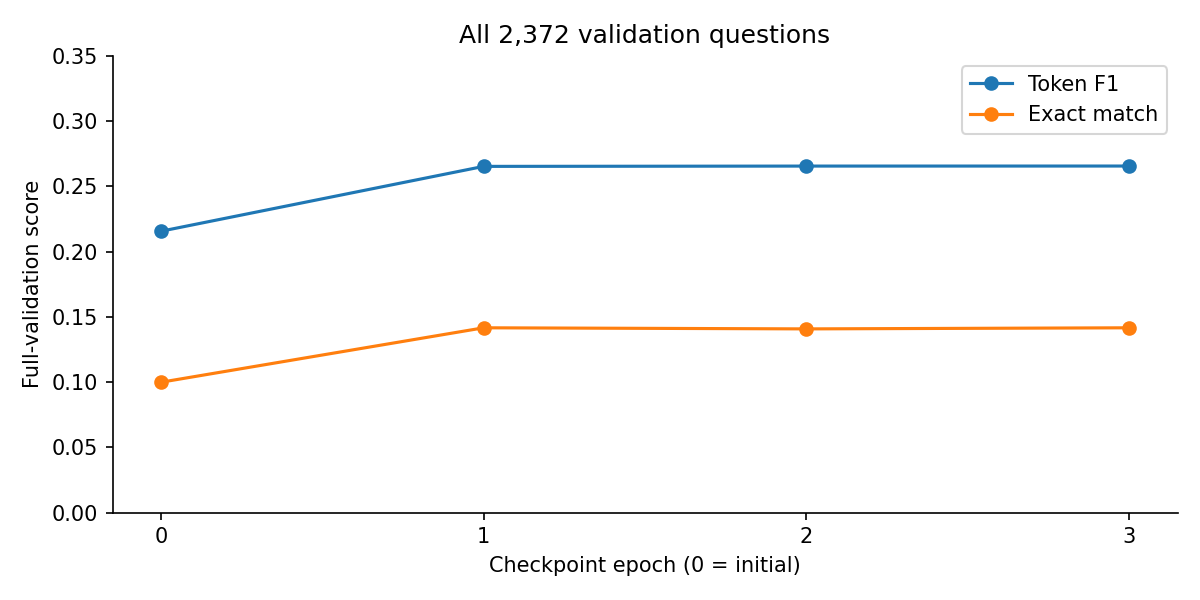

The frozen package and full 325-question test audit are complete. See notebooks 05 and 06 for the final measurements.


In [3]:
validation = read_json("docs/full-generator-validation.json")
assert validation["validation_questions"] == 2372
assert all(row["validation"]["n"] == 2372 for row in validation["candidates"])
assert {row["epoch"] for row in validation["candidates"]} == {0, 1, 2, 3}
table(
    [{"epoch": row["epoch"], "questions": row["validation"]["n"],
      "token F1": row["validation"]["f1"], "exact match": row["validation"]["em"]}
     for row in validation["candidates"]],
    ["epoch", "questions", "token F1", "exact match"],
    "Complete validation: every checkpoint on all 2,372 questions",
)
display(Image(filename=str(ROOT / "assets/plots/full-generator-validation.png")))
print("The frozen package and full 325-question test audit are complete. See notebooks 05 and 06 for the final measurements.")
